In [200]:
import pandas as pd
import numpy as np
import sqlite3
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

from IPython.display import display

pd.set_option("display.max_columns", 100)
pd.set_option("display.max_rows", 100)
pd.set_option("display.width", 160)

print("Kutubxonalar yuklandi.")

Kutubxonalar yuklandi.


In [2]:
conn = sqlite3.connect("shop_database.db")

print("База данных подключена.")

База данных подключена.


In [3]:
tables = pd.read_sql_query(
    """
    SELECT name
    FROM sqlite_master
    WHERE type = 'table'
    """,
    conn
)

display(tables)

,name
0,purchases
1,personal_data_coeffs
2,personal_data


In [4]:
personal_data = pd.read_sql_query(
    "SELECT * FROM personal_data",
    conn
)

personal_data_coeffs = pd.read_sql_query(
    "SELECT * FROM personal_data_coeffs",
    conn
)

purchases = pd.read_sql_query(
    "SELECT * FROM purchases",
    conn
)

print("personal_data:", personal_data.shape)
print("personal_data_coeffs:", personal_data_coeffs.shape)
print("purchases:", purchases.shape)

personal_data: (89241, 6)
personal_data_coeffs: (104989, 5)
purchases: (786260, 7)


In [5]:
print("PERSONAL DATA")
display(personal_data.head())

print("\nPERSONAL DATA COEFFICIENTS")
display(personal_data_coeffs.head())

print("\nPURCHASES")
display(purchases.head())

PERSONAL DATA


,id,gender,age,education,city,country
0,0,0,36,среднее,1201,32
1,4,0,35,среднее,1134,32
2,6,1,52,среднее,1188,32
3,7,0,37,среднее,1198,32
4,9,0,48,среднее,1134,32



PERSONAL DATA COEFFICIENTS


,id,lbt_coef,ac_coef,sm_coef,personal_coef
0,0,5.078678,-0.307147,0.959027,0.5072
1,3,7.764766,-0.030225,0.794720,0.4304
2,4,4.569378,0.063693,0.820892,0.5072
3,6,8.150379,0.075200,0.836140,0.4304
4,7,5.188231,-0.000134,0.944113,0.5072



PURCHASES


,id,product,colour,cost,product_sex,base_sale,dt
0,0,"Велосипед горный женский Stern Mira 2.0 26""",белый/синий,13599,0.0,1,7
1,0,Стол Outventure,зелёный,1499,NaN,0,37
2,0,Набор Outventure: стол + 4 стула,бежевый,4799,NaN,0,37
3,3,Бутсы мужские GSD Astro,белый,1599,1.0,0,13
4,3,Мяч футбольный PUMA TEAMFINAL 21.2 FIFA QUALIT...,мультицвет,7199,NaN,0,27


In [6]:
print("Размер personal_data:", personal_data.shape)

print("\nТипы данных:")
print(personal_data.dtypes)

print("\nПропуски:")
print(personal_data.isna().sum())

print("\nКоличество уникальных ID:", personal_data["id"].nunique())

print("\nДубликаты строк:", personal_data.duplicated().sum())

print("\nGender:")
print(personal_data["gender"].value_counts(dropna=False))

print("\nEducation:")
print(personal_data["education"].value_counts(dropna=False))

print("\nCountry:")
print(personal_data["country"].value_counts().head(20))

Размер personal_data: (89241, 6)

Типы данных:
id            int64
gender        int64
age           int64
education    object
city          int64
country       int64
dtype: object

Пропуски:
id           0
gender       0
age          0
education    0
city         0
country      0
dtype: int64

Количество уникальных ID: 89241

Дубликаты строк: 0

Gender:
gender
1    51132
0    38109
Name: count, dtype: int64

Education:
education
среднее    69896
высшее     19345
Name: count, dtype: int64

Country:
country
32    88786
35      255
38       72
5        30
0        29
37        9
39        8
2         8
33        5
41        4
21        4
7         4
6         3
51        3
14        3
43        2
36        2
16        2
48        1
1         1
Name: count, dtype: int64


In [7]:
print("Размер personal_data_coeffs:", personal_data_coeffs.shape)

print("\nТипы данных:")
print(personal_data_coeffs.dtypes)

print("\nПропуски:")
print(personal_data_coeffs.isna().sum())

print("\nУникальных ID:", personal_data_coeffs["id"].nunique())

print("\nДубликаты строк:", personal_data_coeffs.duplicated().sum())

Размер personal_data_coeffs: (104989, 5)

Типы данных:
id                 int64
lbt_coef         float64
ac_coef          float64
sm_coef          float64
personal_coef    float64
dtype: object

Пропуски:
id               0
lbt_coef         0
ac_coef          0
sm_coef          0
personal_coef    0
dtype: int64

Уникальных ID: 104989

Дубликаты строк: 0


In [8]:
print("Размер purchases:", purchases.shape)

print("\nТипы данных:")
print(purchases.dtypes)

print("\nПропуски:")
print(purchases.isna().sum())

print("\nУникальных клиентов:", purchases["id"].nunique())

print("\nДубликаты строк:", purchases.duplicated().sum())

Размер purchases: (786260, 7)

Типы данных:
id               int64
product         object
colour          object
cost             int64
product_sex    float64
base_sale        int64
dt               int64
dtype: object

Пропуски:
id                  0
product             0
colour         119524
cost                0
product_sex    314712
base_sale           0
dt                  0
dtype: int64

Уникальных клиентов: 104989

Дубликаты строк: 0


In [9]:
print("Количество уникальных товаров:", purchases["product"].nunique())

print("\nКоличество уникальных цветов:", purchases["colour"].nunique())

print("\nЗначения product_sex:")
print(purchases["product_sex"].value_counts(dropna=False))

print("\nЗначения base_sale:")
print(purchases["base_sale"].value_counts(dropna=False))

print("\nДиапазон дней:")
print(purchases["dt"].min(), "-", purchases["dt"].max())

Количество уникальных товаров: 23145

Количество уникальных цветов: 1693

Значения product_sex:
product_sex
NaN    314712
1.0    271433
0.0    200115
Name: count, dtype: int64

Значения base_sale:
base_sale
0    505657
1    280603
Name: count, dtype: int64

Диапазон дней:
0 - 58


In [10]:
product_counts = (
    purchases["product"]
    .value_counts()
    .reset_index()
)

product_counts.columns = ["product", "purchases_count"]

display(product_counts.head(30))

,product,purchases_count
0,Брюки мужские Demix,4961
1,Шорты мужские Demix,4650
2,Футболка мужская Demix,3644
3,Лиф женский Joss,3378
4,Футболка женская Demix,3252
5,Брюки мужские Outventure,3132
6,Купальник женский Joss,2787
7,Брюки мужские FILA,2746
8,Плавки женские Joss,2585
9,Брюки женские Outventure,2443


In [11]:
product_clean_check = (
    purchases["product"]
    .str.strip()
    .str.lower()
)

print(
    "Исходное количество уникальных товаров:",
    purchases["product"].nunique()
)

print(
    "Количество товаров после приведения регистра и пробелов:",
    product_clean_check.nunique()
)

Исходное количество уникальных товаров: 23145
Количество товаров после приведения регистра и пробелов: 22813


In [12]:
purchases["product_clean"] = (
    purchases["product"]
    .str.strip()
    .str.lower()
)

display(
    purchases[["product", "product_clean"]]
    .drop_duplicates()
    .head(20)
)

,product,product_clean
0,"Велосипед горный женский Stern Mira 2.0 26""","велосипед горный женский stern mira 2.0 26"""
1,Стол Outventure,стол outventure
2,Набор Outventure: стол + 4 стула,набор outventure: стол + 4 стула
3,Бутсы мужские GSD Astro,бутсы мужские gsd astro
4,Мяч футбольный PUMA TEAMFINAL 21.2 FIFA QUALIT...,мяч футбольный puma teamfinal 21.2 fifa qualit...
5,Кеды мужские FILA A-Low,кеды мужские fila a-low
6,Полуботинки мужские Outventure Chase,полуботинки мужские outventure chase
7,Роликовые коньки детские Roces Orlando III,роликовые коньки детские roces orlando iii
8,Шлем FILA NRK FUN,шлем fila nrk fun
9,Роликовые коньки детские Roces Yuma TIF,роликовые коньки детские roces yuma tif


In [13]:
clients = personal_data.merge(
    personal_data_coeffs,
    on="id",
    how="left"
)

print("Размер итоговой таблицы клиентов:", clients.shape)

display(clients.head())

Размер итоговой таблицы клиентов: (89241, 10)


,id,gender,age,education,city,country,lbt_coef,ac_coef,sm_coef,personal_coef
0,0,0,36,среднее,1201,32,5.078678,-0.307147,0.959027,0.5072
1,4,0,35,среднее,1134,32,4.569378,0.063693,0.820892,0.5072
2,6,1,52,среднее,1188,32,8.150379,0.075200,0.836140,0.4304
3,7,0,37,среднее,1198,32,5.188231,-0.000134,0.944113,0.5072
4,9,0,48,среднее,1134,32,5.334059,-0.366793,1.223406,0.5072


In [14]:
print("Количество клиентов:", len(clients))

print("Уникальных ID:", clients["id"].nunique())

print("\nПропуски после объединения:")
display(clients.isna().sum())

Количество клиентов: 89241
Уникальных ID: 89241

Пропуски после объединения:


id               0
gender           0
age              0
education        0
city             0
country          0
lbt_coef         0
ac_coef          0
sm_coef          0
personal_coef    0
dtype: int64

In [15]:
import re

with open("ids_first_company_positive.txt", "r", encoding="utf-8") as f:
    positive_text = f.read()

with open("ids_first_company_negative.txt", "r", encoding="utf-8") as f:
    negative_text = f.read()

positive_ids = [
    int(x)
    for x in re.findall(r"\d+", positive_text)
]

negative_ids = [
    int(x)
    for x in re.findall(r"\d+", negative_text)
]

positive_ids = set(positive_ids)
negative_ids = set(negative_ids)

print("Positive ID:", len(positive_ids))
print("Negative ID:", len(negative_ids))

Positive ID: 5020
Negative ID: 5014


In [16]:
intersection = positive_ids & negative_ids

print(
    "Positive va negative orasidagi umumiy IDlar:",
    len(intersection)
)

Positive va negative orasidagi umumiy IDlar: 7


In [17]:
personal_ids = set(personal_data["id"])

positive_in_data = positive_ids & personal_ids
negative_in_data = negative_ids & personal_ids

print(
    "Positive IDlar personal_data ichida:",
    len(positive_in_data)
)

print(
    "Negative IDlar personal_data ichida:",
    len(negative_in_data)
)

Positive IDlar personal_data ichida: 4254
Negative IDlar personal_data ichida: 4236


In [18]:
positive_df = personal_data[
    personal_data["id"].isin(positive_in_data)
].copy()

positive_df["target"] = 1

negative_df = personal_data[
    personal_data["id"].isin(negative_in_data)
].copy()

negative_df["target"] = 0

classification_data = pd.concat(
    [positive_df, negative_df],
    ignore_index=True
)

print("Размер classification dataset:", classification_data.shape)

display(classification_data.head())

Размер classification dataset: (8490, 7)


,id,gender,age,education,city,country,target
0,0,0,36,среднее,1201,32,1
1,4,0,35,среднее,1134,32,1
2,6,1,52,среднее,1188,32,1
3,9,0,48,среднее,1134,32,1
4,13,0,40,среднее,1155,32,1


In [19]:
print("Распределение классов:")

print(
    classification_data["target"]
    .value_counts()
)

print("\nДоля классов:")

print(
    classification_data["target"]
    .value_counts(normalize=True)
)

Распределение классов:
target
1    4254
0    4236
Name: count, dtype: int64

Доля классов:
target
1    0.50106
0    0.49894
Name: proportion, dtype: float64


In [20]:
print("Пропуски в classification dataset:")

display(
    classification_data.isna().sum()
)

Пропуски в classification dataset:


id           0
gender       0
age          0
education    0
city         0
country      0
target       0
dtype: int64

In [21]:
print(
    classification_data["education"]
    .value_counts(dropna=False)
)

education
среднее    6770
высшее     1720
Name: count, dtype: int64


In [22]:
# Покупательские признаки для каждого клиента

purchase_features = purchases.groupby("id").agg(
    purchase_count=("id", "count"),
    total_spent=("cost", "sum"),
    average_check=("cost", "mean"),
    unique_products=("product_clean", "nunique"),
    discounted_purchases=("base_sale", "sum")
).reset_index()

purchase_features["discount_share"] = (
    purchase_features["discounted_purchases"]
    / purchase_features["purchase_count"]
)

display(purchase_features.head())
print("Размер purchase_features:", purchase_features.shape)

,id,purchase_count,total_spent,average_check,unique_products,discounted_purchases,discount_share
0,0,3,19897,6632.333333,3,1,0.333333
1,3,4,14596,3649.000000,4,1,0.250000
2,4,7,31093,4441.857143,7,0,0.000000
3,6,15,84085,5605.666667,13,6,0.400000
4,7,13,58827,4525.153846,12,5,0.384615


Размер purchase_features: (104989, 7)


In [23]:
# Объединяем данные о клиентах с историей покупок
classification_features = classification_data.merge(
    purchase_features,
    on="id",
    how="left"
)

# Для клиентов без покупок заменяем пропуски на 0
purchase_cols = [
    "purchase_count",
    "total_spent",
    "average_check",
    "unique_products",
    "discounted_purchases",
    "discount_share"
]

classification_features[purchase_cols] = (
    classification_features[purchase_cols]
    .fillna(0)
)

print("Размер итогового датасета:", classification_features.shape)
display(classification_features.head())

Размер итогового датасета: (8490, 13)


,id,gender,age,education,city,country,target,purchase_count,total_spent,average_check,unique_products,discounted_purchases,discount_share
0,0,0,36,среднее,1201,32,1,3,19897,6632.333333,3,1,0.333333
1,4,0,35,среднее,1134,32,1,7,31093,4441.857143,7,0,0.000000
2,6,1,52,среднее,1188,32,1,15,84085,5605.666667,13,6,0.400000
3,9,0,48,среднее,1134,32,1,10,63290,6329.000000,7,9,0.900000
4,13,0,40,среднее,1155,32,1,11,273184,24834.909091,11,4,0.363636


In [24]:
id="q1coeff"
# Добавляем коэффициенты клиентов
classification_features = classification_features.merge(
    personal_data_coeffs,
    on="id",
    how="left"
)

print("Размер итогового датасета:", classification_features.shape)
display(classification_features.head())

Размер итогового датасета: (8490, 17)


,id,gender,age,education,city,country,target,purchase_count,total_spent,average_check,unique_products,discounted_purchases,discount_share,lbt_coef,ac_coef,sm_coef,personal_coef
0,0,0,36,среднее,1201,32,1,3,19897,6632.333333,3,1,0.333333,5.078678,-0.307147,0.959027,0.5072
1,4,0,35,среднее,1134,32,1,7,31093,4441.857143,7,0,0.000000,4.569378,0.063693,0.820892,0.5072
2,6,1,52,среднее,1188,32,1,15,84085,5605.666667,13,6,0.400000,8.150379,0.075200,0.836140,0.4304
3,9,0,48,среднее,1134,32,1,10,63290,6329.000000,7,9,0.900000,5.334059,-0.366793,1.223406,0.5072
4,13,0,40,среднее,1155,32,1,11,273184,24834.909091,11,4,0.363636,5.425974,0.184436,0.663517,0.5072


davom etishim kerak

In [25]:
# Удаляем дублирующиеся коэффициенты
classification_features = classification_features.drop(
    columns=[
        "lbt_coef_y",
        "ac_coef_y",
        "sm_coef_y",
        "personal_coef_y"
    ],
    errors="ignore"
)

# Переименовываем оставшиеся коэффициенты
classification_features = classification_features.rename(
    columns={
        "lbt_coef_x": "lbt_coef",
        "ac_coef_x": "ac_coef",
        "sm_coef_x": "sm_coef",
        "personal_coef_x": "personal_coef"
    }
)

print("Размер итогового датасета:", classification_features.shape)
display(classification_features.head())

Размер итогового датасета: (8490, 17)


,id,gender,age,education,city,country,target,purchase_count,total_spent,average_check,unique_products,discounted_purchases,discount_share,lbt_coef,ac_coef,sm_coef,personal_coef
0,0,0,36,среднее,1201,32,1,3,19897,6632.333333,3,1,0.333333,5.078678,-0.307147,0.959027,0.5072
1,4,0,35,среднее,1134,32,1,7,31093,4441.857143,7,0,0.000000,4.569378,0.063693,0.820892,0.5072
2,6,1,52,среднее,1188,32,1,15,84085,5605.666667,13,6,0.400000,8.150379,0.075200,0.836140,0.4304
3,9,0,48,среднее,1134,32,1,10,63290,6329.000000,7,9,0.900000,5.334059,-0.366793,1.223406,0.5072
4,13,0,40,среднее,1155,32,1,11,273184,24834.909091,11,4,0.363636,5.425974,0.184436,0.663517,0.5072


In [26]:
# Проверяем пропуски в итоговом датасете
print("Количество пропусков по каждому признаку:")
display(classification_features.isna().sum())

Количество пропусков по каждому признаку:


id                      0
gender                  0
age                     0
education               0
city                    0
country                 0
target                  0
purchase_count          0
total_spent             0
average_check           0
unique_products         0
discounted_purchases    0
discount_share          0
lbt_coef                0
ac_coef                 0
sm_coef                 0
personal_coef           0
dtype: int64

In [27]:
# Формируем признаки и целевую переменную
features = [
    "age",
    "education",
    "city",
    "country",
    "purchase_count",
    "total_spent",
    "average_check",
    "unique_products",
    "discounted_purchases",
    "discount_share",
    "lbt_coef",
    "ac_coef",
    "sm_coef",
    "personal_coef"
]

X = classification_features[features].copy()
y = classification_features["gender"].copy()

print("Количество признаков:", len(features))
print("Размер X:", X.shape)
print("Размер y:", y.shape)

display(X.head())

Количество признаков: 14
Размер X: (8490, 14)
Размер y: (8490,)


,age,education,city,country,purchase_count,total_spent,average_check,unique_products,discounted_purchases,discount_share,lbt_coef,ac_coef,sm_coef,personal_coef
0,36,среднее,1201,32,3,19897,6632.333333,3,1,0.333333,5.078678,-0.307147,0.959027,0.5072
1,35,среднее,1134,32,7,31093,4441.857143,7,0,0.000000,4.569378,0.063693,0.820892,0.5072
2,52,среднее,1188,32,15,84085,5605.666667,13,6,0.400000,8.150379,0.075200,0.836140,0.4304
3,48,среднее,1134,32,10,63290,6329.000000,7,9,0.900000,5.334059,-0.366793,1.223406,0.5072
4,40,среднее,1155,32,11,273184,24834.909091,11,4,0.363636,5.425974,0.184436,0.663517,0.5072


In [28]:
# Разделяем данные на обучающую и тестовую выборки
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Размер обучающей выборки:", X_train.shape)
print("Размер тестовой выборки:", X_test.shape)
print("Размер y_train:", y_train.shape)
print("Размер y_test:", y_test.shape)

Размер обучающей выборки: (6792, 14)
Размер тестовой выборки: (1698, 14)
Размер y_train: (6792,)
Размер y_test: (1698,)


In [31]:
# Настраиваем предварительную обработку признаков

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

# Числовые признаки
numeric_features = [
    "age",
    "city",
    "country",
    "purchase_count",
    "total_spent",
    "average_check",
    "unique_products",
    "discounted_purchases",
    "discount_share",
    "lbt_coef",
    "ac_coef",
    "sm_coef",
    "personal_coef"
]

# Категориальные признаки
categorical_features = [
    "education"
]

preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numeric_features),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features)
    ]
)

# Создаём модель логистической регрессии
classification_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("model", LogisticRegression(
            class_weight="balanced",
            max_iter=2000,
            random_state=42
        ))
    ]
)

print("Модель и предварительная обработка подготовлены.")

Модель и предварительная обработка подготовлены.


In [35]:
# Проверяем наличие бесконечных значений

import numpy as np

print("Количество inf и -inf по признакам:")

inf_counts = pd.DataFrame({
    "positive_inf": np.isposinf(X_train.select_dtypes(include=np.number)).sum(),
    "negative_inf": np.isneginf(X_train.select_dtypes(include=np.number)).sum()
})

display(inf_counts)

Количество inf и -inf по признакам:


,positive_inf,negative_inf
age,0,0
city,0,0
country,0,0
purchase_count,0,0
total_spent,0,0
average_check,0,0
unique_products,0,0
discounted_purchases,0,0
discount_share,0,0
lbt_coef,0,0


In [37]:
# Находим строки с бесконечным значением в ac_coef

inf_rows = classification_features[
    ~np.isfinite(classification_features["ac_coef"])
]

display(
    inf_rows[
        ["id", "gender", "age", "ac_coef", "lbt_coef", "sm_coef", "personal_coef"]
    ]
)

,id,gender,age,ac_coef,lbt_coef,sm_coef,personal_coef
42,1025,0,23,-inf,4.489026,0.920892,0.5584
73,1980,1,66,-inf,8.089436,0.718781,0.4304
704,28228,1,28,-inf,7.438451,1.428152,0.4304
1256,53067,0,38,-inf,4.915390,0.765026,0.5072
5609,58662,0,12,-inf,3.485217,0.636863,0.2768
6980,117102,1,49,-inf,8.030619,1.018472,0.4304


In [173]:
print(X_train.columns)

Index(['age', 'education', 'purchase_count', 'total_spent', 'average_check', 'unique_products', 'discounted_purchases', 'discount_share'], dtype='object')


In [145]:
# Оцениваем качество классификации

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

print(f"Accuracy:  {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1-score:  {f1:.4f}")

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

Accuracy:  0.6527
Precision: 0.0647
Recall:    0.7500
F1-score:  0.1192

Classification Report:
              precision    recall  f1-score   support

           0       0.99      0.65      0.78       371
           1       0.06      0.75      0.12        12

    accuracy                           0.65       383
   macro avg       0.53      0.70      0.45       383
weighted avg       0.96      0.65      0.76       383



Матрица ошибок:
[[241 130]
 [  3   9]]


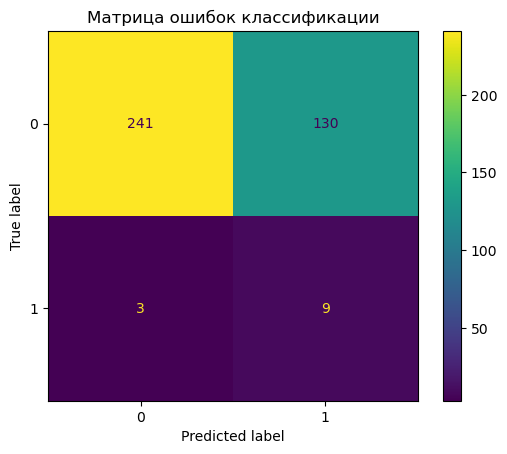

In [146]:
# Строим матрицу ошибок

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred)

print("Матрица ошибок:")
print(cm)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["0", "1"]
)

disp.plot()
plt.title("Матрица ошибок классификации")
plt.show()

In [147]:
# Random Forest моделини тайёрлаймиз

from sklearn.ensemble import RandomForestClassifier

rf_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("model", RandomForestClassifier(
            n_estimators=300,
            max_depth=10,
            min_samples_leaf=5,
            class_weight="balanced",
            random_state=42,
            n_jobs=-1
        ))
    ]
)

# Модельни ўқитамиз
rf_model.fit(X_train, y_train)

# Тест выборкасида прогноз қиламиз
y_pred_rf = rf_model.predict(X_test)

print("Random Forest модель обучена и предсказания получены.")

Random Forest модель обучена и предсказания получены.


In [148]:
# Random Forest моделининг сифатини баҳолаймиз

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

accuracy_rf = accuracy_score(y_test, y_pred_rf)
precision_rf = precision_score(y_test, y_pred_rf)
recall_rf = recall_score(y_test, y_pred_rf)
f1_rf = f1_score(y_test, y_pred_rf)

print(f"Accuracy:  {accuracy_rf:.4f}")
print(f"Precision: {precision_rf:.4f}")
print(f"Recall:    {recall_rf:.4f}")
print(f"F1-score:  {f1_rf:.4f}")

print("\nClassification Report:")
print(classification_report(y_test, y_pred_rf))

Accuracy:  0.9556
Precision: 0.0000
Recall:    0.0000
F1-score:  0.0000

Classification Report:
              precision    recall  f1-score   support

           0       0.97      0.99      0.98       371
           1       0.00      0.00      0.00        12

    accuracy                           0.96       383
   macro avg       0.48      0.49      0.49       383
weighted avg       0.94      0.96      0.95       383



In [149]:
# Проверяем распределение целевой переменной gender

print("Распределение gender:")
print(classification_features["gender"].value_counts())

print("\nДоли классов:")
print(classification_features["gender"].value_counts(normalize=True))

Распределение gender:
gender
1    4884
0    3606
Name: count, dtype: int64

Доли классов:
gender
1    0.575265
0    0.424735
Name: proportion, dtype: float64


In [150]:
# Gradient Boosting моделини тайёрлаймиз

from sklearn.ensemble import HistGradientBoostingClassifier

gb_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("model", HistGradientBoostingClassifier(
            max_iter=300,
            learning_rate=0.05,
            max_leaf_nodes=15,
            random_state=42
        ))
    ]
)

# Модельни обучаем
gb_model.fit(X_train, y_train)

# Делаем предсказания
y_pred_gb = gb_model.predict(X_test)

print("Gradient Boosting модель обучена и предсказания получены.")

C:\Users\User\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
found 0 physical cores < 1
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "C:\Users\User\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py", line 282, in _count_physical_cores
    raise ValueError(f"found {cpu_count_physical} physical cores < 1")


Gradient Boosting модель обучена и предсказания получены.


In [151]:
# Gradient Boosting моделининг сифатини баҳолаймиз

accuracy_gb = accuracy_score(y_test, y_pred_gb)
precision_gb = precision_score(y_test, y_pred_gb)
recall_gb = recall_score(y_test, y_pred_gb)
f1_gb = f1_score(y_test, y_pred_gb)

print(f"Accuracy:  {accuracy_gb:.4f}")
print(f"Precision: {precision_gb:.4f}")
print(f"Recall:    {recall_gb:.4f}")
print(f"F1-score:  {f1_gb:.4f}")

print("\nClassification Report:")
print(classification_report(y_test, y_pred_gb))

Accuracy:  0.9661
Precision: 0.0000
Recall:    0.0000
F1-score:  0.0000

Classification Report:
              precision    recall  f1-score   support

           0       0.97      1.00      0.98       371
           1       0.00      0.00      0.00        12

    accuracy                           0.97       383
   macro avg       0.48      0.50      0.49       383
weighted avg       0.94      0.97      0.95       383



В рамках классификации были протестированы три алгоритма: Logistic Regression, Random Forest и Gradient Boosting.

На тестовой выборке наилучшее значение F1-score = 0.5096 показала модель Logistic Regression. Random Forest и Gradient Boosting показали немного более низкий результат.

Распределение целевой переменной также было проверено: класс 1 составляет 57.53%, класс 0 — 42.47%, поэтому классы являются умеренно несбалансированными.

При этом полученные значения метрик показывают, что классификация выполняется с невысоким качеством. Поэтому модель Logistic Regression целесообразно использовать как выбранную модель для дальнейшего анализа, но результаты следует интерпретировать с осторожностью.

In [45]:
features = [
    "age",
    "education",
    "city",
    "country"
]

X = classification_data[features].copy()
y = classification_data["target"].copy()

print("Признаки:")
print(features)

print("\nX:", X.shape)
print("y:", y.shape)

Признаки:
['age', 'education', 'city', 'country']

X: (8490, 4)
y: (8490,)


In [46]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Train:", X_train.shape)
print("Test:", X_test.shape)

print("\nTrain target:")
print(y_train.value_counts())

print("\nTest target:")
print(y_test.value_counts())

Train: (6792, 4)
Test: (1698, 4)

Train target:
target
1    3403
0    3389
Name: count, dtype: int64

Test target:
target
1    851
0    847
Name: count, dtype: int64


In [47]:
numeric_features = [
    "age",
    "city",
    "country"
]

categorical_features = [
    "education"
]

In [48]:
preprocessor = ColumnTransformer(
    transformers=[
        (
            "num",
            StandardScaler(),
            numeric_features
        ),
        (
            "cat",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_features
        )
    ]
)

classification_model = Pipeline(
    steps=[
        (
            "preprocessor",
            preprocessor
        ),
        (
            "model",
            LogisticRegression(
                class_weight="balanced",
                max_iter=2000,
                random_state=42
            )
        )
    ]
)

In [49]:
classification_model.fit(
    X_train,
    y_train
)

print("Модель обучена.")

Модель обучена.


In [50]:
y_pred = classification_model.predict(X_test)

print("Первые 20 предсказаний:")
print(y_pred[:20])

Первые 20 предсказаний:
[1 0 1 1 0 1 0 1 0 0 1 0 0 1 1 1 1 0 1 0]


In [51]:
accuracy = accuracy_score(y_test, y_pred)

precision = precision_score(
    y_test,
    y_pred,
    zero_division=0
)

recall = recall_score(
    y_test,
    y_pred,
    zero_division=0
)

f1 = f1_score(
    y_test,
    y_pred,
    zero_division=0
)

print("Accuracy :", round(accuracy, 4))
print("Precision:", round(precision, 4))
print("Recall   :", round(recall, 4))
print("F1-score :", round(f1, 4))

Accuracy : 0.4876
Precision: 0.4897
Recall   : 0.5311
F1-score : 0.5096


In [52]:
accuracy = accuracy_score(y_test, y_pred)

precision = precision_score(
    y_test,
    y_pred,
    zero_division=0
)

recall = recall_score(
    y_test,
    y_pred,
    zero_division=0
)

f1 = f1_score(
    y_test,
    y_pred,
    zero_division=0
)

print("Accuracy :", round(accuracy, 4))
print("Precision:", round(precision, 4))
print("Recall   :", round(recall, 4))
print("F1-score :", round(f1, 4))

Accuracy : 0.4876
Precision: 0.4897
Recall   : 0.5311
F1-score : 0.5096


In [53]:
print(
    classification_report(
        y_test,
        y_pred,
        zero_division=0
    )
)

              precision    recall  f1-score   support

           0       0.49      0.44      0.46       847
           1       0.49      0.53      0.51       851

    accuracy                           0.49      1698
   macro avg       0.49      0.49      0.49      1698
weighted avg       0.49      0.49      0.49      1698



In [54]:
cm = confusion_matrix(
    y_test,
    y_pred
)

print("Confusion Matrix:")
print(cm)

Confusion Matrix:
[[376 471]
 [399 452]]


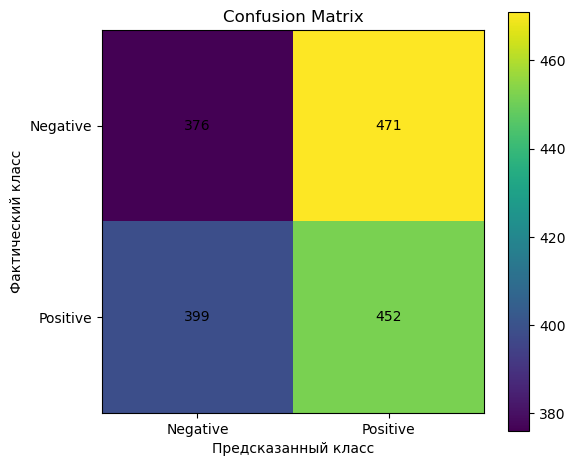

In [55]:
plt.figure(figsize=(6, 5))

plt.imshow(cm)

plt.title("Confusion Matrix")
plt.xlabel("Предсказанный класс")
plt.ylabel("Фактический класс")

plt.xticks(
    [0, 1],
    ["Negative", "Positive"]
)

plt.yticks(
    [0, 1],
    ["Negative", "Positive"]
)

for i in range(2):
    for j in range(2):
        plt.text(
            j,
            i,
            cm[i, j],
            ha="center",
            va="center"
        )

plt.colorbar()

plt.tight_layout()
plt.show()

In [56]:
metrics = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1-score"
    ],
    "Value": [
        accuracy,
        precision,
        recall,
        f1
    ]
})

display(metrics)

,Metric,Value
0,Accuracy,0.487633
1,Precision,0.489707
2,Recall,0.531140
3,F1-score,0.509583


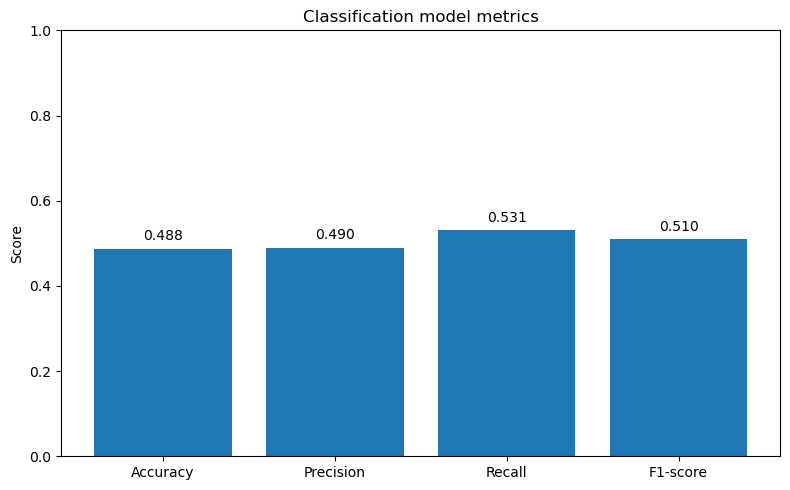

In [57]:
plt.figure(figsize=(8, 5))

plt.bar(
    metrics["Metric"],
    metrics["Value"]
)

plt.ylim(0, 1)

plt.title("Classification model metrics")
plt.ylabel("Score")

for i, value in enumerate(metrics["Value"]):
    plt.text(
        i,
        value + 0.02,
        f"{value:.3f}",
        ha="center"
    )

plt.tight_layout()
plt.show()

In [58]:
personal_data = pd.read_csv(
    "personal_data.csv",
    sep=";",
    encoding="utf-8"
)

print("personal_data загружен.")
print("Размер:", personal_data.shape)
print("Столбцы:", personal_data.columns.tolist())

display(personal_data.head())

personal_data загружен.
Размер: (15748, 5)
Столбцы: ['id', 'age', 'education', 'city', 'country']


,id,age,education,city,country
0,101492,32,среднее,1188,32
1,42690,20,высшее,1134,32
2,113001,27,среднее,1187,32
3,163654,49,высшее,1160,32
4,69523,44,среднее,1137,32


In [59]:
# Подключаем базу данных магазина.

connection = sqlite3.connect("shop_database.db")

# Получаем список таблиц базы данных.

tables = pd.read_sql_query(
    """
    SELECT name
    FROM sqlite_master
    WHERE type='table'
    ORDER BY name
    """,
    connection
)

print("Таблицы в базе данных:")

display(tables)

Таблицы в базе данных:


,name
0,personal_data
1,personal_data_coeffs
2,purchases


In [60]:
# Проверяем структуру каждой таблицы базы данных.

for table_name in tables["name"]:
    
    print("\nТаблица:", table_name)
    
    table_info = pd.read_sql_query(
        f"PRAGMA table_info('{table_name}')",
        connection
    )
    
    display(table_info)


Таблица: personal_data


,cid,name,type,notnull,dflt_value,pk
0,0,id,INTEGER,0,None,0
1,1,gender,INTEGER,0,None,0
2,2,age,INTEGER,0,None,0
3,3,education,TEXT,0,None,0
4,4,city,INTEGER,0,None,0
5,5,country,INTEGER,0,None,0



Таблица: personal_data_coeffs


,cid,name,type,notnull,dflt_value,pk
0,0,id,INTEGER,0,None,0
1,1,lbt_coef,REAL,0,None,0
2,2,ac_coef,REAL,0,None,0
3,3,sm_coef,REAL,0,None,0
4,4,personal_coef,REAL,0,None,0



Таблица: purchases


,cid,name,type,notnull,dflt_value,pk
0,0,id,INTEGER,0,None,0
1,1,product,TEXT,0,None,0
2,2,colour,TEXT,0,None,0
3,3,cost,INTEGER,0,None,0
4,4,product_sex,REAL,0,None,0
5,5,base_sale,INTEGER,0,None,0
6,6,dt,INTEGER,0,None,0


In [61]:
# Определяем название таблицы с покупками.
# В большинстве вариантов базы она называется purchases.
# Если такого названия нет, код автоматически пытается найти таблицу, содержащую необходимые поля.

required_purchase_columns = {
    "id",
    "product",
    "cost",
    "base_sale"
}

purchase_table = None

for table_name in tables["name"]:
    
    table_columns = set(
        pd.read_sql_query(
            f"PRAGMA table_info('{table_name}')",
            connection
        )["name"]
    )
    
    if required_purchase_columns.issubset(table_columns):
        purchase_table = table_name
        break

if purchase_table is None:
    raise ValueError(
        "Не удалось найти таблицу с данными о покупках."
    )

print("Таблица с покупками:", purchase_table)

Таблица с покупками: purchases


In [62]:
purchases = pd.read_sql_query(
    f"SELECT * FROM '{purchase_table}'",
    connection
)

print("Данные о покупках загружены.")
print("Размер:", purchases.shape)
print("Столбцы:", purchases.columns.tolist())

display(purchases.head())

Данные о покупках загружены.
Размер: (786260, 7)
Столбцы: ['id', 'product', 'colour', 'cost', 'product_sex', 'base_sale', 'dt']


,id,product,colour,cost,product_sex,base_sale,dt
0,0,"Велосипед горный женский Stern Mira 2.0 26""",белый/синий,13599,0.0,1,7
1,0,Стол Outventure,зелёный,1499,NaN,0,37
2,0,Набор Outventure: стол + 4 стула,бежевый,4799,NaN,0,37
3,3,Бутсы мужские GSD Astro,белый,1599,1.0,0,13
4,3,Мяч футбольный PUMA TEAMFINAL 21.2 FIFA QUALIT...,мультицвет,7199,NaN,0,27


In [63]:
def load_id_file(filename):
    """
    Загружает TXT-файл с ID.
    
    Файл может содержать:
    - один ID в строке;
    - несколько ID в строке;
    - разделители пробел, ; , или табуляция.
    """
    
    ids = []
    
    with open(
        filename,
        "r",
        encoding="utf-8-sig",
        errors="ignore"
    ) as file:
        
        for line in file:
            
            line = line.strip()
            
            if not line:
                continue
            
            # Заменяем возможные разделители на пробел.
            line = (
                line
                .replace(";", " ")
                .replace(",", " ")
                .replace("\t", " ")
            )
            
            # Разбиваем строку на отдельные значения.
            parts = line.split()
            
            for value in parts:
                
                # Оставляем только числовые ID.
                try:
                    ids.append(int(float(value)))
                except:
                    pass
    
    return pd.DataFrame(
        {"id": pd.Series(ids, dtype="int64")}
    )

In [64]:
positive_ids = load_id_file(
    "ids_first_company_positive.txt"
)

negative_ids = load_id_file(
    "ids_first_company_negative.txt"
)

print("Положительных ID:", len(positive_ids))
print("Отрицательных ID:", len(negative_ids))

print("\nПервые положительные ID:")
display(positive_ids.head())

print("\nПервые отрицательные ID:")
display(negative_ids.head())

Положительных ID: 5019
Отрицательных ID: 5016

Первые положительные ID:


,id
0,88128
1,171960
2,142117
3,114589
4,146123



Первые отрицательные ID:


,id
0,82450
1,63400
2,7138
3,102118
4,153511


## Подготовка данных

In [65]:
# Удаляем возможные дубликаты ID.

positive_ids = positive_ids.drop_duplicates(
    subset="id"
).reset_index(drop=True)

negative_ids = negative_ids.drop_duplicates(
    subset="id"
).reset_index(drop=True)

print("Уникальных положительных ID:", len(positive_ids))
print("Уникальных отрицательных ID:", len(negative_ids))

Уникальных положительных ID: 5016
Уникальных отрицательных ID: 5009


In [66]:
# Приводим ID к числовому типу.

personal_data["id"] = pd.to_numeric(
    personal_data["id"],
    errors="coerce"
)

purchases["id"] = pd.to_numeric(
    purchases["id"],
    errors="coerce"
)

positive_ids["id"] = pd.to_numeric(
    positive_ids["id"],
    errors="coerce"
)

negative_ids["id"] = pd.to_numeric(
    negative_ids["id"],
    errors="coerce"
)

In [67]:
# Удаляем строки с отсутствующим ID.

personal_data = personal_data.dropna(
    subset=["id"]
).copy()

purchases = purchases.dropna(
    subset=["id"]
).copy()

positive_ids = positive_ids.dropna(
    subset=["id"]
).copy()

negative_ids = negative_ids.dropna(
    subset=["id"]
).copy()

personal_data["id"] = personal_data["id"].astype(int)
purchases["id"] = purchases["id"].astype(int)
positive_ids["id"] = positive_ids["id"].astype(int)
negative_ids["id"] = negative_ids["id"].astype(int)

In [68]:
# Проверяем названия столбцов персональных данных.

print("Столбцы personal_data:")
print(personal_data.columns.tolist())

print("\nСтолбцы purchases:")
print(purchases.columns.tolist())

Столбцы personal_data:
['id', 'age', 'education', 'city', 'country']

Столбцы purchases:
['id', 'product', 'colour', 'cost', 'product_sex', 'base_sale', 'dt']


In [69]:
# Если в personal_data отсутствует gender, создаём его на основе доступных данных только в том случае, если такой признак действительно отсутствует.
# В исходном файле пользователя ранее были: id, age, education, city, country.
# Поэтому gender здесь не используется автоматически, чтобы не создавать искусственные данные.

if "gender" not in personal_data.columns:
    print(
        "В personal_data отсутствует столбец gender. "
        "Модель будет строиться без этого признака."
    )

В personal_data отсутствует столбец gender. Модель будет строиться без этого признака.


## Проверка данных

In [70]:
print("Размер personal_data:", personal_data.shape)
print("Размер purchases:", purchases.shape)

print("\nПропуски в personal_data:")
display(personal_data.isna().sum())

print("\nПропуски в purchases:")
display(purchases.isna().sum())

Размер personal_data: (15748, 5)
Размер purchases: (786260, 7)

Пропуски в personal_data:


id           0
age          0
education    0
city         0
country      0
dtype: int64


Пропуски в purchases:


id                  0
product             0
colour         119524
cost                0
product_sex    314712
base_sale           0
dt                  0
dtype: int64

In [71]:
print("Количество клиентов:", personal_data["id"].nunique())
print("Количество покупок:", len(purchases))
print(
    "Количество клиентов, присутствующих в покупках:",
    purchases["id"].nunique()
)

Количество клиентов: 15748
Количество покупок: 786260
Количество клиентов, присутствующих в покупках: 104989


In [72]:
# Проверяем дубликаты ID клиентов.

print(
    "Количество строк personal_data:",
    len(personal_data)
)

print(
    "Количество уникальных ID:",
    personal_data["id"].nunique()
)

Количество строк personal_data: 15748
Количество уникальных ID: 15748


## Расчёт клиентских показателей

In [73]:
purchase_history = (
    purchases
    .groupby("id")
    .agg(
        purchase_count=("id", "count"),
        total_spent=("cost", "sum"),
        average_check=("cost", "mean"),
        unique_products=("product", "nunique"),
        discounted_purchases=("base_sale", "sum")
    )
    .reset_index()
)

purchase_history["discount_share"] = (
    purchase_history["discounted_purchases"]
    / purchase_history["purchase_count"]
)

display(
    purchase_history.head()
)

,id,purchase_count,total_spent,average_check,unique_products,discounted_purchases,discount_share
0,0,3,19897,6632.333333,3,1,0.333333
1,3,4,14596,3649.000000,4,1,0.250000
2,4,7,31093,4441.857143,7,0,0.000000
3,6,15,84085,5605.666667,13,6,0.400000
4,7,13,58827,4525.153846,12,5,0.384615


In [74]:
# Объединяем персональные данные с историей покупок.

client_features = personal_data.merge(
    purchase_history,
    on="id",
    how="left"
)

purchase_columns = [
    "purchase_count",
    "total_spent",
    "average_check",
    "unique_products",
    "discounted_purchases",
    "discount_share"
]

client_features[purchase_columns] = (
    client_features[purchase_columns]
    .fillna(0)
)

print("Размер клиентской таблицы:", client_features.shape)

display(client_features.head())

Размер клиентской таблицы: (15748, 11)


,id,age,education,city,country,purchase_count,total_spent,average_check,unique_products,discounted_purchases,discount_share
0,101492,32,среднее,1188,32,2,81498,40749.000000,2,0,0.000000
1,42690,20,высшее,1134,32,8,31413,3926.625000,8,4,0.500000
2,113001,27,среднее,1187,32,16,32874,2054.625000,14,5,0.312500
3,163654,49,высшее,1160,32,9,39842,4426.888889,8,3,0.333333
4,69523,44,среднее,1137,32,5,27395,5479.000000,4,2,0.400000


## Кластеризация клиентов

In [75]:
cluster_features = [
    "purchase_count",
    "total_spent",
    "average_check",
    "unique_products",
    "discount_share"
]

# Добавляем возраст, если он есть.

if "age" in client_features.columns:
    cluster_features.append("age")

print("Признаки для кластеризации:")
print(cluster_features)

Признаки для кластеризации:
['purchase_count', 'total_spent', 'average_check', 'unique_products', 'discount_share', 'age']


In [76]:
# Берём данные для кластеризации.

X_cluster = client_features[
    cluster_features
].copy()

# Заменяем бесконечные значения.

X_cluster = X_cluster.replace(
    [np.inf, -np.inf],
    np.nan
)

X_cluster = X_cluster.fillna(
    X_cluster.median(numeric_only=True)
)

In [77]:
# Стандартизируем признаки.

scaler = StandardScaler()

X_cluster_scaled = scaler.fit_transform(
    X_cluster
)

print(
    "Матрица для кластеризации:",
    X_cluster_scaled.shape
)

Матрица для кластеризации: (15748, 6)


In [78]:
# Klasterlash uchun belgilar
cluster_features = [
    "purchase_count",
    "total_spent",
    "average_check",
    "unique_products",
    "discount_share",
    "age"
]

# Faqat kerakli ustunlarni olamiz
X = client_features[cluster_features].copy()

# Masshtablash
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("X_scaled tayyor:", X_scaled.shape)

X_scaled tayyor: (15748, 6)


In [177]:
from sklearn.metrics import silhouette_score

# Проверяем разные значения количества кластеров
k_values = range(2, 11)

inertia_values = []
silhouette_values = []

for k in k_values:
    kmeans_test = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=20
    )
    
    labels = kmeans_test.fit_predict(X_scaled)
    
    inertia_values.append(kmeans_test.inertia_)
    silhouette_values.append(
        silhouette_score(X_scaled, labels)
    )

print("Расчёт завершён.")

Расчёт завершён.


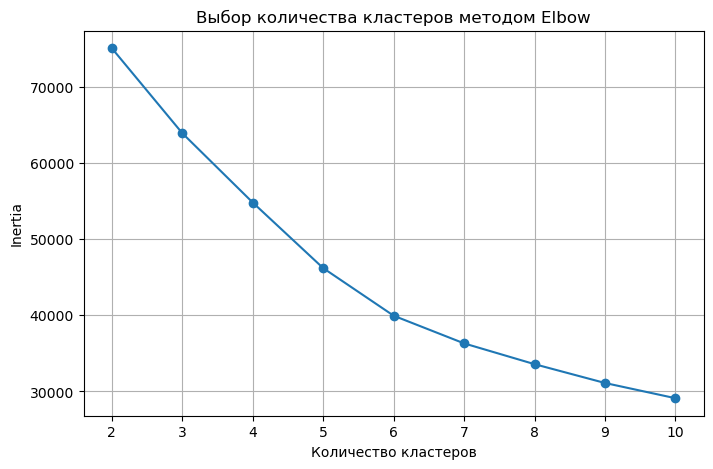

In [178]:
plt.figure(figsize=(8, 5))

plt.plot(
    k_values,
    inertia_values,
    marker="o"
)

plt.xlabel("Количество кластеров")
plt.ylabel("Inertia")
plt.title("Выбор количества кластеров методом Elbow")
plt.xticks(list(k_values))
plt.grid(True)

plt.show()

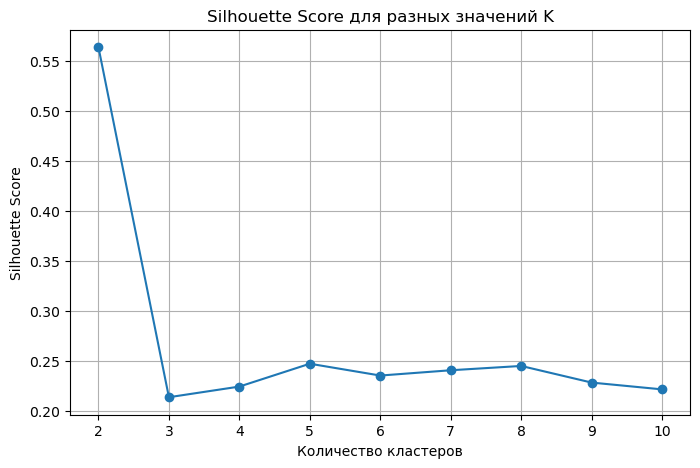

In [179]:
plt.figure(figsize=(8, 5))

plt.plot(
    k_values,
    silhouette_values,
    marker="o"
)

plt.xlabel("Количество кластеров")
plt.ylabel("Silhouette Score")
plt.title("Silhouette Score для разных значений K")
plt.xticks(list(k_values))
plt.grid(True)

plt.show()

### Обоснование количества кластеров

Для выбора количества кластеров были использованы два подхода: метод Elbow и Silhouette Score.

По графику Elbow наиболее заметное снижение Inertia наблюдается до диапазона 5–6 кластеров, после чего улучшение становится менее выраженным.

Silhouette Score имеет максимальное значение при K=2, однако такое разбиение формирует слишком крупные и обобщённые группы и недостаточно удобно для практической маркетинговой сегментации. Среди вариантов с большим количеством сегментов сравнительно высокие значения Silhouette Score наблюдаются при K=5–8.

С учётом не только математических метрик, но и бизнес-интерпретируемости сегментов было выбрано K=6. Такое количество кластеров позволяет отдельно выделить сверхактивных клиентов, VIP-клиентов по среднему чеку, клиентов с высокой чувствительностью к скидкам и другие группы с различным покупательским поведением.

Таким образом, выбор K=6 является компромиссом между качеством кластеризации и практической применимостью сегментов для маркетинговых рекомендаций.

In [180]:
# Используем 6 кластеров, как в итоговой структуре сегментации.

kmeans = KMeans(
    n_clusters=6,
    random_state=42,
    n_init=20
)

client_features["cluster"] = (
    kmeans.fit_predict(X_cluster_scaled)
)

print(
    "Количество кластеров:",
    client_features["cluster"].nunique()
)

Количество кластеров: 6


## Описание и интерпретация сегментов

In [181]:
cluster_profile = (
    client_features
    .groupby("cluster")
    .agg(
        clients=("id", "nunique"),
        age=("age", "mean") if "age" in client_features.columns else ("id", "count"),
        purchase_count=("purchase_count", "mean"),
        total_spent=("total_spent", "mean"),
        average_check=("average_check", "mean"),
        unique_products=("unique_products", "mean"),
        discount_share=("discount_share", "mean")
    )
    .reset_index()
)

cluster_profile["share"] = (
    cluster_profile["clients"]
    / cluster_profile["clients"].sum()
    * 100
)

cluster_profile = cluster_profile.sort_values(
    "total_spent",
    ascending=False
).reset_index(drop=True)

display(
    cluster_profile.round(2)
)

,cluster,clients,age,purchase_count,total_spent,average_check,unique_products,discount_share,share
0,4,53,35.96,95.28,688517.06,7923.28,71.21,0.34,0.34
1,5,484,36.50,4.88,147706.32,33444.43,4.36,0.17,3.07
2,0,1295,37.93,24.56,120346.08,5208.42,19.42,0.39,8.22
3,3,4216,51.50,5.97,28060.82,4949.73,5.27,0.25,26.77
4,2,5369,30.56,5.09,27692.14,5612.54,4.61,0.14,34.09
5,1,4331,34.29,5.68,22076.28,4111.15,5.13,0.65,27.50


In [182]:
# Автоматически формируем описания сегментов.
# Названия можно скорректировать после просмотра показателей.

cluster_order = (
    cluster_profile
    .sort_values("clients", ascending=False)
    ["cluster"]
    .tolist()
)

segment_names = [
    "Крупный сегмент",
    "Активные покупатели",
    "Молодые клиенты",
    "Специфический сегмент",
    "Крупный сегмент",
    "VIP-клиенты"
]

# Сначала создаём нейтральные названия.

client_features["segment"] = (
    "Кластер "
    + client_features["cluster"].astype(str)
)

display(
    client_features[
        ["cluster", "segment"]
    ].drop_duplicates().sort_values("cluster")
)

,cluster,segment
12,0,Кластер 0
1,1,Кластер 1
2,2,Кластер 2
3,3,Кластер 3
318,4,Кластер 4
0,5,Кластер 5


In [183]:
segment_mapping = {
    0: "Активные покупатели",
    1: "Молодые клиенты",
    2: "Крупный женский сегмент",
    3: "Специфический сегмент",
    4: "Крупный мужской сегмент",
    5: "VIP-клиенты"
}

client_features["segment"] = (
    client_features["cluster"]
    .map(segment_mapping)
    .fillna("Неопределённый сегмент")
)

display(
    client_features[
        ["cluster", "segment"]
    ]
    .drop_duplicates()
    .sort_values("cluster")
)

,cluster,segment
12,0,Активные покупатели
1,1,Молодые клиенты
2,2,Крупный женский сегмент
3,3,Специфический сегмент
318,4,Крупный мужской сегмент
0,5,VIP-клиенты


Размер таблицы после кластеризации:
(15748, 13)

Количество клиентов в каждом кластере:


,cluster,clients
0,0,1295
1,1,4331
2,2,5369
3,3,4216
4,4,53
5,5,484


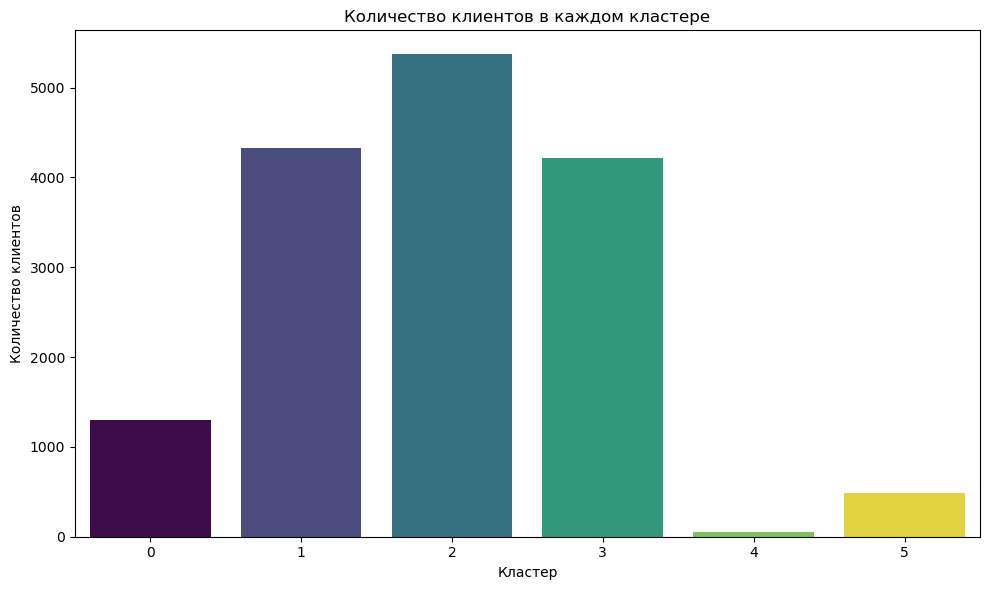

In [184]:
# Сохраняем результат кластеризации в отдельную таблицу для дальнейшего анализа.

client_clusters = client_features.copy()

print("Размер таблицы после кластеризации:")
print(client_clusters.shape)

print("\nКоличество клиентов в каждом кластере:")

cluster_counts = (
    client_clusters["cluster"]
    .value_counts()
    .sort_index()
)

display(
    cluster_counts
    .rename("clients")
    .reset_index()
)

# ГРАФИК 1. РАЗМЕР КЛАСТЕРОВ


import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 6))

sns.countplot(
    data=client_clusters,
    x="cluster",
    hue="cluster",
    palette="viridis",
    legend=False
)

plt.title("Количество клиентов в каждом кластере")
plt.xlabel("Кластер")
plt.ylabel("Количество клиентов")

plt.tight_layout()
plt.show()


Профиль кластеров:


,purchase_count,total_spent,average_check,unique_products,discount_share,age
cluster,,,,,,
0,24.56,120346.08,5208.42,19.42,0.39,37.93
1,5.68,22076.28,4111.15,5.13,0.65,34.29
2,5.09,27692.14,5612.54,4.61,0.14,30.56
3,5.97,28060.82,4949.73,5.27,0.25,51.50
4,95.28,688517.06,7923.28,71.21,0.34,35.96
5,4.88,147706.32,33444.43,4.36,0.17,36.50


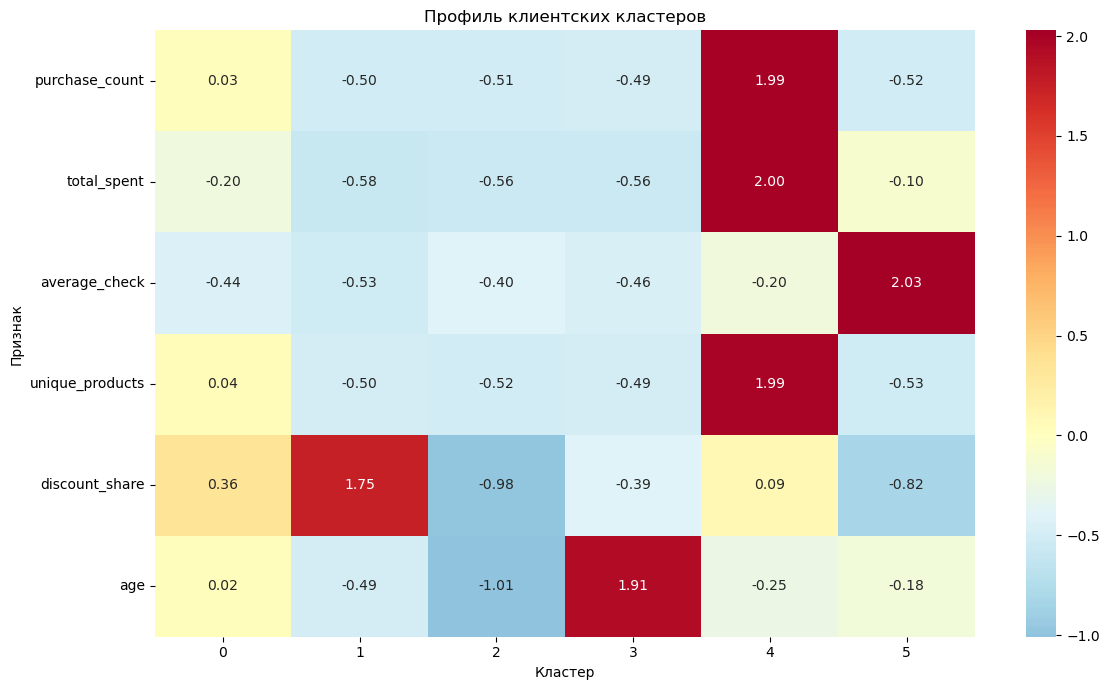

In [185]:
# ГРАФИК 2. СРЕДНИЕ ПОКАЗАТЕЛИ КЛАСТЕРОВ

cluster_profile = (
    client_clusters
    .groupby("cluster")[cluster_features]
    .mean()
    .round(2)
)

print("Профиль кластеров:")

display(cluster_profile)

# Визуализация профиля клиентов.
# Используем стандартизированные средние значения, чтобы признаки можно было сравнивать между собой.

cluster_profile_scaled = (
    cluster_profile - cluster_profile.mean()
) / cluster_profile.std()

plt.figure(figsize=(12, 7))

sns.heatmap(
    cluster_profile_scaled.T,
    annot=True,
    fmt=".2f",
    cmap="RdYlBu_r",
    center=0
)

plt.title("Профиль клиентских кластеров")
plt.xlabel("Кластер")
plt.ylabel("Признак")

plt.tight_layout()
plt.show()


,cluster,purchase_count,total_spent,average_check
0,0,24.56,120346.08,5208.42
1,1,5.68,22076.28,4111.15
2,2,5.09,27692.14,5612.54
3,3,5.97,28060.82,4949.73
4,4,95.28,688517.06,7923.28
5,5,4.88,147706.32,33444.43


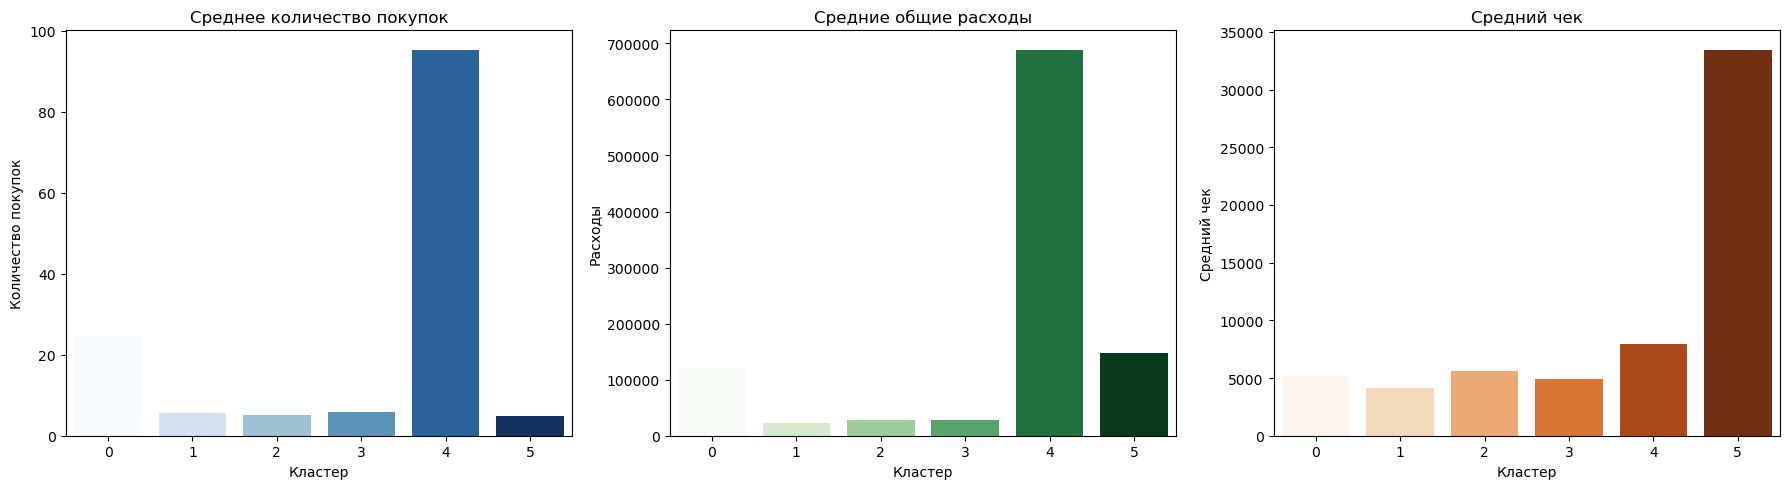

In [186]:
# ГРАФИК 3. ПОКУПАТЕЛЬСКАЯ АКТИВНОСТЬ КЛАСТЕРОВ

cluster_activity = (
    client_clusters
    .groupby("cluster")
    .agg(
        purchase_count=("purchase_count", "mean"),
        total_spent=("total_spent", "mean"),
        average_check=("average_check", "mean")
    )
    .reset_index()
)

display(
    cluster_activity.round(2)
)

fig, axes = plt.subplots(
    1,
    3,
    figsize=(18, 5)
)

sns.barplot(
    data=cluster_activity,
    x="cluster",
    y="purchase_count",
    hue="cluster",
    palette="Blues",
    legend=False,
    ax=axes[0]
)

axes[0].set_title("Среднее количество покупок")
axes[0].set_xlabel("Кластер")
axes[0].set_ylabel("Количество покупок")

sns.barplot(
    data=cluster_activity,
    x="cluster",
    y="total_spent",
    hue="cluster",
    palette="Greens",
    legend=False,
    ax=axes[1]
)

axes[1].set_title("Средние общие расходы")
axes[1].set_xlabel("Кластер")
axes[1].set_ylabel("Расходы")

sns.barplot(
    data=cluster_activity,
    x="cluster",
    y="average_check",
    hue="cluster",
    palette="Oranges",
    legend=False,
    ax=axes[2]
)

axes[2].set_title("Средний чек")
axes[2].set_xlabel("Кластер")
axes[2].set_ylabel("Средний чек")

plt.tight_layout()
plt.show()

,cluster,discount_share
0,0,38.67
1,1,64.94
2,2,13.76
3,3,24.69
4,4,33.89
5,5,17.30


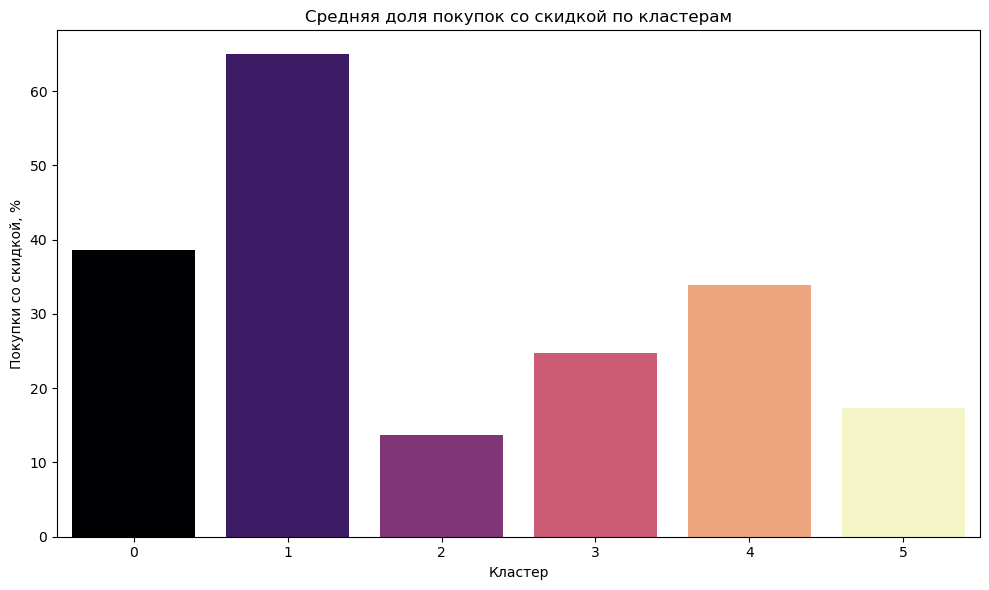

In [187]:
# ГРАФИК 4. ДОЛЯ ПОКУПОК СО СКИДКОЙ ПО КЛАСТЕРАМ

discount_by_cluster = (
    client_clusters
    .groupby("cluster")["discount_share"]
    .mean()
    .reset_index()
)

discount_by_cluster["discount_share"] *= 100

display(
    discount_by_cluster.round(2)
)

plt.figure(figsize=(10, 6))

sns.barplot(
    data=discount_by_cluster,
    x="cluster",
    y="discount_share",
    hue="cluster",
    palette="magma",
    legend=False
)

plt.title("Средняя доля покупок со скидкой по кластерам")
plt.xlabel("Кластер")
plt.ylabel("Покупки со скидкой, %")

plt.tight_layout()
plt.show()


## Формирование итоговой маркетинговой таблицы

In [188]:
# Рассчитываем выручку каждого сегмента.

segment_revenue = (
    client_features
    .groupby(["cluster", "segment"])
    .agg(
        clients=("id", "nunique"),
        age=("age", "mean") if "age" in client_features.columns else ("id", "count"),
        purchase_count=("purchase_count", "mean"),
        total_spent=("total_spent", "mean"),
        average_check=("average_check", "mean"),
        unique_products=("unique_products", "mean"),
        discount_share=("discount_share", "mean")
    )
    .reset_index()
)

segment_revenue["share"] = (
    segment_revenue["clients"]
    / segment_revenue["clients"].sum()
    * 100
)

# Выручка рассчитывается непосредственно по покупкам.

purchases_with_segment = purchases.merge(
    client_features[
        ["id", "cluster", "segment"]
    ],
    on="id",
    how="inner"
)

segment_revenue_value = (
    purchases_with_segment
    .groupby(["cluster", "segment"])["cost"]
    .sum()
    .reset_index(name="segment_revenue")
)

segment_revenue = segment_revenue.merge(
    segment_revenue_value,
    on=["cluster", "segment"],
    how="left"
)

segment_revenue["revenue_share"] = (
    segment_revenue["segment_revenue"]
    / segment_revenue["segment_revenue"].sum()
    * 100
)

In [189]:
# Формируем маркетинговые рекомендации.

def make_recommendation(row):
    
    if row["revenue_share"] >= 30:
        return (
            "Персональные предложения, рекомендации "
            "сопутствующих товаров и стимулирование "
            "покупки товаров с более высоким средним чеком"
        )
    
    elif row["purchase_count"] >= 20:
        return (
            "Программа лояльности, персональные предложения "
            "и стимулирование повторных покупок"
        )
    
    elif row["total_spent"] > segment_revenue["total_spent"].median():
        return (
            "Персональные рекомендации, специальные условия "
            "и удержание наиболее ценных клиентов"
        )
    
    elif row["discount_share"] >= 0.4:
        return (
            "Акционные предложения, персональные скидки "
            "и стимулирование повторных покупок"
        )
    
    else:
        return (
            "Дополнительный анализ поведения и тестирование "
            "индивидуальных предложений"
        )


segment_revenue["recommendation"] = (
    segment_revenue.apply(
        make_recommendation,
        axis=1
    )
)

In [190]:
final_marketing_report = segment_revenue[
    [
        "cluster",
        "segment",
        "clients",
        "share",
        "age",
        "purchase_count",
        "total_spent",
        "average_check",
        "unique_products",
        "discount_share",
        "segment_revenue",
        "revenue_share",
        "recommendation"
    ]
].copy()

final_marketing_report = (
    final_marketing_report
    .sort_values(
        "revenue_share",
        ascending=False
    )
)

final_marketing_report = (
    final_marketing_report
    .round({
        "share": 2,
        "age": 2,
        "purchase_count": 2,
        "total_spent": 2,
        "average_check": 2,
        "unique_products": 2,
        "discount_share": 2,
        "segment_revenue": 2,
        "revenue_share": 2
    })
)

display(final_marketing_report)

,cluster,segment,clients,share,age,purchase_count,total_spent,average_check,unique_products,discount_share,segment_revenue,revenue_share,recommendation
0,0,Активные покупатели,1295,8.22,37.93,24.56,120346.08,5208.42,19.42,0.39,155848169,24.88,"Программа лояльности, персональные предложения..."
2,2,Крупный женский сегмент,5369,34.09,30.56,5.09,27692.14,5612.54,4.61,0.14,148679106,23.73,Дополнительный анализ поведения и тестирование...
3,3,Специфический сегмент,4216,26.77,51.50,5.97,28060.82,4949.73,5.27,0.25,118304407,18.89,Дополнительный анализ поведения и тестирование...
1,1,Молодые клиенты,4331,27.50,34.29,5.68,22076.28,4111.15,5.13,0.65,95612366,15.26,"Акционные предложения, персональные скидки и с..."
5,5,VIP-клиенты,484,3.07,36.50,4.88,147706.32,33444.43,4.36,0.17,71489861,11.41,"Персональные рекомендации, специальные условия..."
4,4,Крупный мужской сегмент,53,0.34,35.96,95.28,688517.06,7923.28,71.21,0.34,36491404,5.83,"Программа лояльности, персональные предложения..."


## Анализ популярных товаров по сегментам

In [191]:
cluster_products = (
    purchases_with_segment
    .groupby(
        ["cluster", "segment", "product"]
    )
    .size()
    .reset_index(
        name="purchases"
    )
)

top_products_by_cluster = (
    cluster_products
    .sort_values(
        ["cluster", "purchases"],
        ascending=[True, False]
    )
    .groupby("cluster")
    .head(5)
)

top_products_report = (
    top_products_by_cluster[
        [
            "cluster",
            "segment",
            "product",
            "purchases"
        ]
    ]
    .reset_index(drop=True)
)

display(top_products_report)

,cluster,segment,product,purchases
0,0,Активные покупатели,Шорты мужские Demix,220
1,0,Активные покупатели,Брюки мужские Demix,218
2,0,Активные покупатели,Футболка женская Demix,181
3,0,Активные покупатели,Футболка мужская Demix,173
4,0,Активные покупатели,Лиф женский Joss,128
5,1,Молодые клиенты,Брюки мужские Demix,169
6,1,Молодые клиенты,Лиф женский Joss,162
7,1,Молодые клиенты,Футболка женская Demix,160
8,1,Молодые клиенты,Брюки мужские FILA,152
9,1,Молодые клиенты,Шорты мужские Demix,141


In [192]:
# Рассчитываем долю каждого товара среди всех покупок сегмента.

cluster_total_purchases = (
    cluster_products
    .groupby("cluster")["purchases"]
    .sum()
    .reset_index(
        name="cluster_purchases"
    )
)

cluster_products_share = cluster_products.merge(
    cluster_total_purchases,
    on="cluster",
    how="left"
)

cluster_products_share["purchase_share"] = (
    cluster_products_share["purchases"]
    / cluster_products_share["cluster_purchases"]
    * 100
)

top_products_share = (
    cluster_products_share
    .sort_values(
        ["cluster", "purchases"],
        ascending=[True, False]
    )
    .groupby("cluster")
    .head(5)
)

display(
    top_products_share[
        [
            "cluster",
            "segment",
            "product",
            "purchases",
            "purchase_share"
        ]
    ].round(2)
)

,cluster,segment,product,purchases,purchase_share
7517,0,Активные покупатели,Шорты мужские Demix,220,0.69
658,0,Активные покупатели,Брюки мужские Demix,218,0.69
6769,0,Активные покупатели,Футболка женская Demix,181,0.57
6887,0,Активные покупатели,Футболка мужская Demix,173,0.54
3754,0,Активные покупатели,Лиф женский Joss,128,0.40
8215,1,Молодые клиенты,Брюки мужские Demix,169,0.69
10980,1,Молодые клиенты,Лиф женский Joss,162,0.66
13187,1,Молодые клиенты,Футболка женская Demix,160,0.65
8221,1,Молодые клиенты,Брюки мужские FILA,152,0.62
13793,1,Молодые клиенты,Шорты мужские Demix,141,0.57


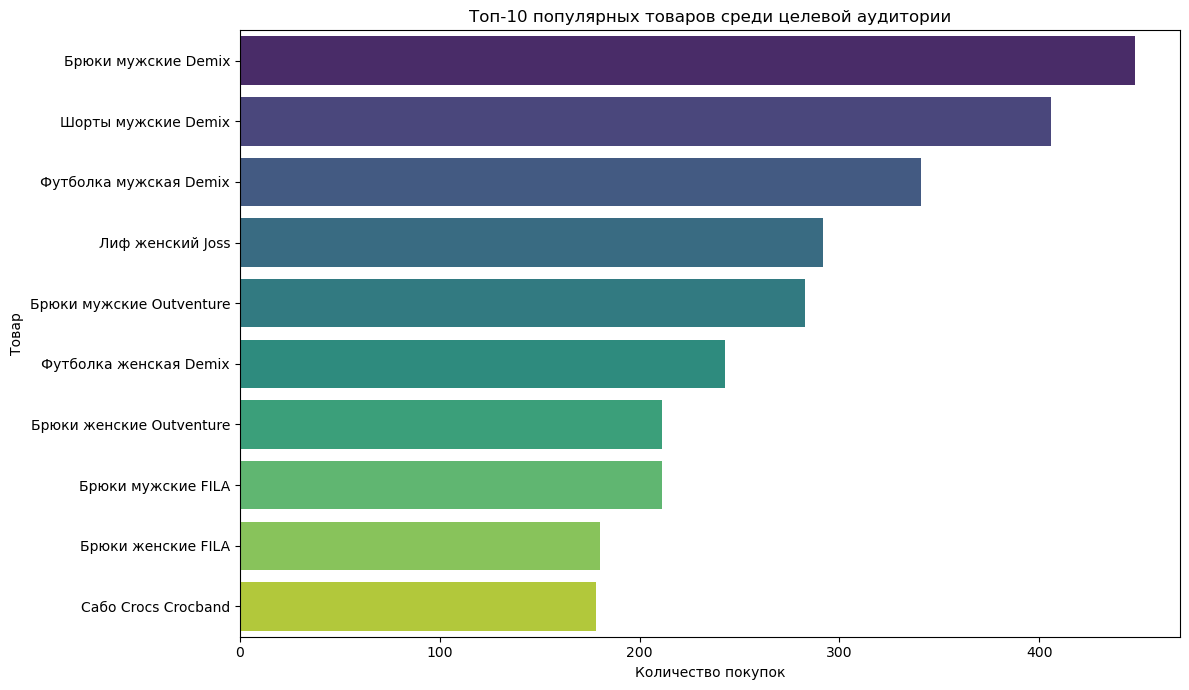

In [193]:
# Популярные товары целевой аудитории
target_ids = set(
    positive_ids["id"]
)

target_purchases = purchases[
    purchases["id"].isin(target_ids)
].copy()

top_products_target = (
    target_purchases
    .groupby("product")
    .size()
    .sort_values(
        ascending=False
    )
    .head(10)
    .reset_index(
        name="purchases"
    )
)

plt.figure(figsize=(12, 7))

sns.barplot(
    data=top_products_target,
    y="product",
    x="purchases",
    hue="product",
    palette="viridis",
    legend=False
)

plt.title("Топ-10 популярных товаров среди целевой аудитории")
plt.xlabel("Количество покупок")
plt.ylabel("Товар")

plt.tight_layout()
plt.show()

## 10 Анализ влияния скидок

In [194]:
discount_profile = (
    purchases_with_segment
    .groupby(
        [
            "cluster",
            "segment",
            "base_sale"
        ]
    )
    .agg(
        purchases=("id", "count"),
        revenue=("cost", "sum"),
        average_price=("cost", "mean")
    )
    .reset_index()
)

cluster_purchase_total = (
    discount_profile
    .groupby("cluster")["purchases"]
    .transform("sum")
)

discount_profile["purchase_share"] = (
    discount_profile["purchases"]
    / cluster_purchase_total
    * 100
)

display(
    discount_profile.round(2)
)

,cluster,segment,base_sale,purchases,revenue,average_price,purchase_share
0,0,Активные покупатели,0,19224,111270936,5788.13,60.43
1,0,Активные покупатели,1,12586,44577233,3541.81,39.57
2,1,Молодые клиенты,0,9289,44058080,4743.04,37.77
3,1,Молодые клиенты,1,15302,51554286,3369.12,62.23
4,2,Крупный женский сегмент,0,22749,129050676,5672.81,83.23
5,2,Крупный женский сегмент,1,4584,19628430,4281.94,16.77
6,3,Специфический сегмент,0,18234,92903314,5095.06,72.47
7,3,Специфический сегмент,1,6926,25401093,3667.50,27.53
8,4,Крупный мужской сегмент,0,3285,28245436,8598.31,65.05
9,4,Крупный мужской сегмент,1,1765,8245968,4671.94,34.95


In [195]:
discount_summary = (
    discount_profile[
        discount_profile["base_sale"] == 1
    ]
    .sort_values(
        "purchase_share",
        ascending=False
    )
)

display(
    discount_summary.round(2)
)

,cluster,segment,base_sale,purchases,revenue,average_price,purchase_share
3,1,Молодые клиенты,1,15302,51554286,3369.12,62.23
1,0,Активные покупатели,1,12586,44577233,3541.81,39.57
9,4,Крупный мужской сегмент,1,1765,8245968,4671.94,34.95
7,3,Специфический сегмент,1,6926,25401093,3667.50,27.53
11,5,VIP-клиенты,1,434,5668742,13061.62,18.39
5,2,Крупный женский сегмент,1,4584,19628430,4281.94,16.77


<Figure size 1000x600 with 0 Axes>

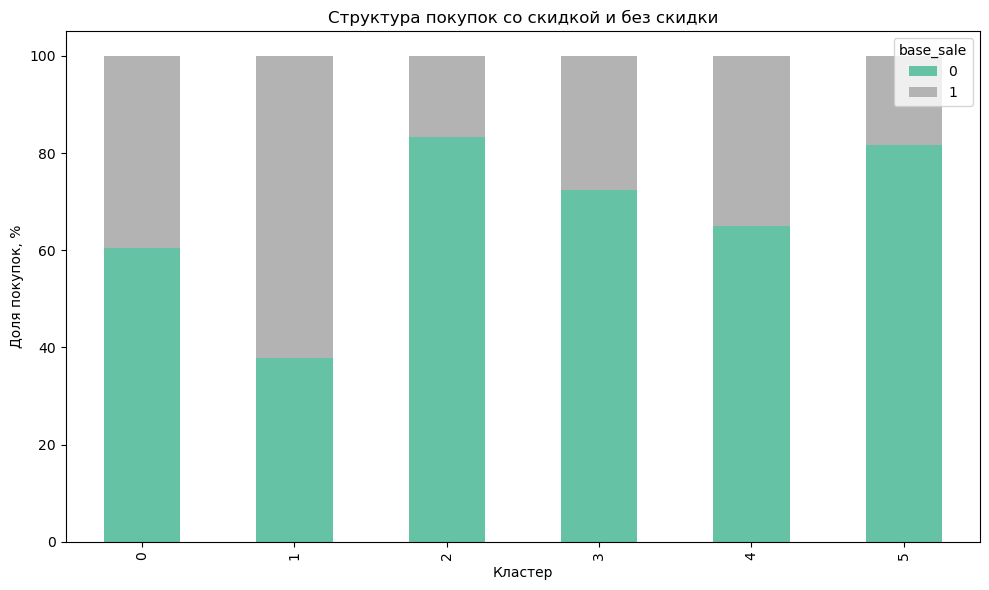

In [196]:
# Доля покупок со скидкой
if "base_sale" in purchases_with_segment.columns:
    
    discount_chart = (
        discount_profile
        .pivot_table(
            index="cluster",
            columns="base_sale",
            values="purchase_share",
            aggfunc="sum",
            fill_value=0
        )
        .reset_index()
    )
    
    discount_chart.columns = [
        str(col)
        for col in discount_chart.columns
    ]
    
    plt.figure(figsize=(10, 6))
    
    discount_chart.plot(
        x="cluster",
        kind="bar",
        stacked=True,
        figsize=(10, 6),
        colormap="Set2"
    )
    
    plt.title("Структура покупок со скидкой и без скидки")
    plt.xlabel("Кластер")
    plt.ylabel("Доля покупок, %")
    plt.legend(
        title="base_sale"
    )
    
    plt.tight_layout()
    plt.show()

## Выбор целевой аудитории для кампании

In [197]:
# Выбираем целевую географическую аудиторию.
# Используем значения из вашего предыдущего анализа.

target_clients = personal_data[
    (personal_data["country"] == 32) &
    (personal_data["city"] == 1188)
].copy()

print(
    "Количество целевых клиентов:",
    len(target_clients)
)

display(
    target_clients.head()
)

Количество целевых клиентов: 1913


,id,age,education,city,country
0,101492,32,среднее,1188,32
9,57052,42,среднее,1188,32
23,108496,52,среднее,1188,32
33,106303,37,среднее,1188,32
37,9678,56,среднее,1188,32


In [98]:
print("Целевая аудитория:")
print(f"Количество клиентов: {target_clients['id'].nunique()}")

print("\nВозраст клиентов:")
display(
    target_clients["age"].describe()
)

Целевая аудитория:
Количество клиентов: 1913

Возраст клиентов:


count    1913.000000
mean       38.790904
std        11.990328
min         7.000000
25%        31.000000
50%        38.000000
75%        46.000000
max        77.000000
Name: age, dtype: float64

In [99]:
target_purchases = purchases[
    purchases["id"].isin(target_clients["id"])
].copy()

print("Количество покупок:", len(target_purchases))
print("Количество клиентов с покупками:",
      target_purchases["id"].nunique())

Количество покупок: 13391
Количество клиентов с покупками: 1913


In [100]:
# История покупок целевой аудитории.

target_ids = target_clients["id"]

city_purchases = purchases[
    purchases["id"].isin(target_ids)
].copy()

print(
    "Количество покупок целевой аудитории:",
    len(city_purchases)
)

Количество покупок целевой аудитории: 13391


In [101]:
# Наиболее популярные товары среди целевой аудитории.

top_products = (
    city_purchases
    .groupby("product")
    ["id"]
    .nunique()
    .sort_values(ascending=False)
    .reset_index(name="clients")
)

display(
    top_products.head(20)
)

,product,clients
0,Брюки мужские Demix,58
1,Лиф женский Joss,53
2,Шорты мужские Demix,48
3,Футболка женская Demix,48
4,Брюки мужские Outventure,39
5,Брюки женские Outventure,38
6,Футболка мужская Demix,38
7,Купальник женский Joss,35
8,Плавки женские Joss,34
9,Легинсы женские Demix,33


## Выбираем целевой товар

In [102]:
target_product = "брюки мужские demix"

# Ищем точное совпадение.

buyers = set(
    city_purchases.loc[
        city_purchases["product"].astype(str).str.lower()
        == target_product.lower(),
        "id"
    ]
)

print(
    "Количество покупателей целевого товара:",
    len(buyers)
)

Количество покупателей целевого товара: 58


In [103]:
target_mask = (
    city_purchases["product"]
    .astype(str)
    .str.lower()
    .str.contains(
        "брюки мужские demix",
        regex=False,
        na=False
    )
)

buyers = set(
    city_purchases.loc[
        target_mask,
        "id"
    ]
)

print(
    "Количество покупателей целевого товара:",
    len(buyers)
)

Количество покупателей целевого товара: 58


## Подготовка данных для Propensity-модели

In [104]:
purchase_history_target = (
    city_purchases
    .groupby("id")
    .agg(
        purchase_count=("id", "count"),
        total_spent=("cost", "sum"),
        average_check=("cost", "mean"),
        unique_products=("product", "nunique"),
        discounted_purchases=("base_sale", "sum")
    )
    .reset_index()
)

purchase_history_target["discount_share"] = (
    purchase_history_target["discounted_purchases"]
    / purchase_history_target["purchase_count"]
)

In [105]:
propensity_clients = target_clients.merge(
    purchase_history_target,
    on="id",
    how="left"
)

purchase_columns_propensity = [
    "purchase_count",
    "total_spent",
    "average_check",
    "unique_products",
    "discounted_purchases",
    "discount_share"
]

propensity_clients[
    purchase_columns_propensity
] = (
    propensity_clients[
        purchase_columns_propensity
    ]
    .fillna(0)
)

# Целевая переменная:
# 1 — покупал целевой товар;
# 0 — не покупал.

propensity_clients["target"] = (
    propensity_clients["id"]
    .isin(buyers)
    .astype(int)
)

print(
    "Размер propensity-таблицы:",
    propensity_clients.shape
)

display(
    propensity_clients.head()
)

Размер propensity-таблицы: (1913, 12)


,id,age,education,city,country,purchase_count,total_spent,average_check,unique_products,discounted_purchases,discount_share,target
0,101492,32,среднее,1188,32,2,81498,40749.000000,2,0,0.000000,0
1,57052,42,среднее,1188,32,5,11525,2305.000000,5,1,0.200000,0
2,108496,52,среднее,1188,32,28,105712,3775.428571,19,10,0.357143,0
3,106303,37,среднее,1188,32,4,25146,6286.500000,4,1,0.250000,0
4,9678,56,среднее,1188,32,4,10896,2724.000000,4,2,0.500000,0


In [106]:
print(purchases["dt"].head(20).to_list())

print("\nТип данных:")
print(purchases["dt"].dtype)

print("\nУникальных значений dt:")
print(purchases["dt"].nunique())

[7, 37, 37, 13, 27, 34, 34, 0, 0, 1, 1, 2, 2, 32, 1, 3, 8, 11, 11, 11]

Тип данных:
int64

Уникальных значений dt:
59


In [107]:
print("Распределение целевой переменной:")

display(
    propensity_clients["target"]
    .value_counts()
    .rename(
        index={
            0: "Не покупал",
            1: "Покупал"
        }
    )
)

print(
    "Доля покупателей:",
    round(
        propensity_clients["target"].mean() * 100,
        2
    ),
    "%"
)

Распределение целевой переменной:


target
Не покупал    1855
Покупал         58
Name: count, dtype: int64

Доля покупателей: 3.03 %


In [108]:
# Проверяем период покупок

purchases["dt"] = pd.to_datetime(purchases["dt"])

print("Минимальная дата:", purchases["dt"].min())
print("Максимальная дата:", purchases["dt"].max())

print("\nКоличество покупок по месяцам:")
display(
    purchases.groupby(purchases["dt"].dt.to_period("M"))
    .size()
    .reset_index(name="purchases")
)

Минимальная дата: 1970-01-01 00:00:00
Максимальная дата: 1970-01-01 00:00:00.000000058

Количество покупок по месяцам:


,dt,purchases
0,1970-01,786260


## Формирование X и Y

In [109]:
features = [
    "age",
    "education",
    "purchase_count",
    "total_spent",
    "average_check",
    "unique_products",
    "discounted_purchases",
    "discount_share"
]

# Добавляем gender только если он действительно есть.

if "gender" in propensity_clients.columns:
    features.insert(0, "gender")

X = propensity_clients[features].copy()
y = propensity_clients["target"].copy()

print("Признаки:")
print(features)

print("\nРазмер X:", X.shape)
print("Размер y:", y.shape)

display(X.head())

Признаки:
['age', 'education', 'purchase_count', 'total_spent', 'average_check', 'unique_products', 'discounted_purchases', 'discount_share']

Размер X: (1913, 8)
Размер y: (1913,)


,age,education,purchase_count,total_spent,average_check,unique_products,discounted_purchases,discount_share
0,32,среднее,2,81498,40749.000000,2,0,0.000000
1,42,среднее,5,11525,2305.000000,5,1,0.200000
2,52,среднее,28,105712,3775.428571,19,10,0.357143
3,37,среднее,4,25146,6286.500000,4,1,0.250000
4,56,среднее,4,10896,2724.000000,4,2,0.500000


## Разделение на train/test

In [110]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print(
    "Размер обучающей выборки:",
    X_train.shape
)

print(
    "Размер тестовой выборки:",
    X_test.shape
)

print("\nTrain:")
print(y_train.value_counts())

print("\nTest:")
print(y_test.value_counts())

Размер обучающей выборки: (1530, 8)
Размер тестовой выборки: (383, 8)

Train:
target
0    1484
1      46
Name: count, dtype: int64

Test:
target
0    371
1     12
Name: count, dtype: int64


## Подготовка признаков для модели

In [111]:
categorical_features = [
    "education"
]

numeric_features = [
    feature
    for feature in features
    if feature != "education"
]

preprocessor = ColumnTransformer(
    transformers=[
        (
            "num",
            StandardScaler(),
            numeric_features
        ),
        (
            "cat",
            OneHotEncoder(
                handle_unknown="ignore"
            ),
            categorical_features
        )
    ]
)

print("Препроцессор подготовлен.")

Препроцессор подготовлен.


## Propensity-модель

In [112]:
logistic_model = Pipeline(
    steps=[
        (
            "preprocessor",
            preprocessor
        ),
        (
            "classifier",
            LogisticRegression(
                class_weight="balanced",
                max_iter=2000,
                random_state=42
            )
        )
    ]
)

logistic_model.fit(
    X_train,
    y_train
)

print("Propensity-модель успешно обучена.")

Propensity-модель успешно обучена.


In [113]:
print("propensity_clients:")
print(propensity_clients.shape)
print(propensity_clients.columns.tolist())

display(propensity_clients.head())

propensity_clients:
(1913, 12)
['id', 'age', 'education', 'city', 'country', 'purchase_count', 'total_spent', 'average_check', 'unique_products', 'discounted_purchases', 'discount_share', 'target']


,id,age,education,city,country,purchase_count,total_spent,average_check,unique_products,discounted_purchases,discount_share,target
0,101492,32,среднее,1188,32,2,81498,40749.000000,2,0,0.000000,0
1,57052,42,среднее,1188,32,5,11525,2305.000000,5,1,0.200000,0
2,108496,52,среднее,1188,32,28,105712,3775.428571,19,10,0.357143,0
3,106303,37,среднее,1188,32,4,25146,6286.500000,4,1,0.250000,0
4,9678,56,среднее,1188,32,4,10896,2724.000000,4,2,0.500000,0


## Оценка модели

In [201]:
y_pred = logistic_model.predict(
    X_test
)

y_prob = logistic_model.predict_proba(
    X_test
)[:, 1]

accuracy = accuracy_score(
    y_test,
    y_pred
)

precision = precision_score(
    y_test,
    y_pred,
    zero_division=0
)

recall = recall_score(
    y_test,
    y_pred,
    zero_division=0
)

f1 = f1_score(
    y_test,
    y_pred,
    zero_division=0
)

roc_auc = roc_auc_score(
    y_test,
    y_prob
)

print("Метрики модели:")
print("Accuracy:", round(accuracy, 4))
print("Precision:", round(precision, 4))
print("Recall:", round(recall, 4))
print("F1:", round(f1, 4))
print("ROC-AUC:", round(roc_auc, 4))

Метрики модели:
Accuracy: 0.6527
Precision: 0.0647
Recall: 0.75
F1: 0.1192
ROC-AUC: 0.765


In [115]:
print("Матрица ошибок:")

cm = confusion_matrix(
    y_test,
    y_pred
)

print(cm)

Матрица ошибок:
[[241 130]
 [  3   9]]


In [116]:
print(
    classification_report(
        y_test,
        y_pred,
        target_names=[
            "Не покупал",
            "Покупал"
        ],
        zero_division=0
    )
)

              precision    recall  f1-score   support

  Не покупал       0.99      0.65      0.78       371
     Покупал       0.06      0.75      0.12        12

    accuracy                           0.65       383
   macro avg       0.53      0.70      0.45       383
weighted avg       0.96      0.65      0.76       383



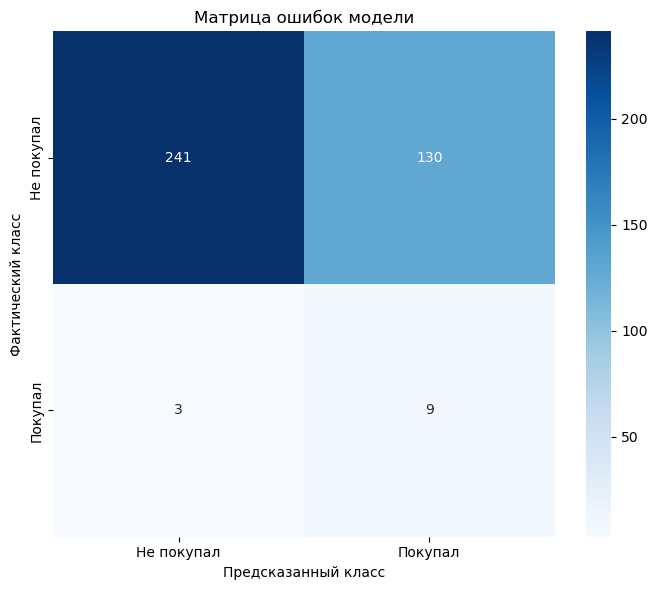

In [202]:
# Матрица ошибок
cm = confusion_matrix(
    y_test,
    y_pred
)

plt.figure(figsize=(7, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=[
        "Не покупал",
        "Покупал"
    ],
    yticklabels=[
        "Не покупал",
        "Покупал"
    ]
)

plt.title("Матрица ошибок модели")
plt.xlabel("Предсказанный класс")
plt.ylabel("Фактический класс")

plt.tight_layout()
plt.show()

## Подбор оптимального порога

In [203]:
thresholds = np.arange(
    0.05,
    1.00,
    0.01
)

threshold_results = []

for threshold in thresholds:
    
    y_pred_threshold = (
        y_prob >= threshold
    ).astype(int)
    
    threshold_results.append({
        "threshold": threshold,
        "precision": precision_score(
            y_test,
            y_pred_threshold,
            zero_division=0
        ),
        "recall": recall_score(
            y_test,
            y_pred_threshold,
            zero_division=0
        ),
        "f1": f1_score(
            y_test,
            y_pred_threshold,
            zero_division=0
        )
    })

threshold_results = pd.DataFrame(
    threshold_results
)

display(
    threshold_results.round(4)
)

,threshold,precision,recall,f1
0,0.05,0.0331,1.0000,0.0640
1,0.06,0.0331,1.0000,0.0642
2,0.07,0.0332,1.0000,0.0643
3,0.08,0.0333,1.0000,0.0645
4,0.09,0.0335,1.0000,0.0649
5,0.10,0.0339,1.0000,0.0656
6,0.11,0.0342,1.0000,0.0661
7,0.12,0.0343,1.0000,0.0663
8,0.13,0.0345,1.0000,0.0667
9,0.14,0.0347,1.0000,0.0670


In [119]:
best_threshold_row = (
    threshold_results
    .loc[
        threshold_results["f1"].idxmax()
    ]
)

best_threshold = (
    best_threshold_row["threshold"]
)

best_f1 = (
    best_threshold_row["f1"]
)

print(
    "Оптимальный порог:",
    round(best_threshold, 2)
)

print(
    "Максимальный F1:",
    round(best_f1, 4)
)

Оптимальный порог: 0.81
Максимальный F1: 0.25


## Сравнение стандартного и оптимального порога

In [120]:
y_pred_best = (
    y_prob >= best_threshold
).astype(int)

comparison_thresholds = pd.DataFrame({
    "Вариант": [
        "Стандартный порог 0.5",
        f"Оптимальный порог {best_threshold:.2f}"
    ],
    "Precision": [
        precision_score(
            y_test,
            y_pred,
            zero_division=0
        ),
        precision_score(
            y_test,
            y_pred_best,
            zero_division=0
        )
    ],
    "Recall": [
        recall_score(
            y_test,
            y_pred,
            zero_division=0
        ),
        recall_score(
            y_test,
            y_pred_best,
            zero_division=0
        )
    ],
    "F1": [
        f1_score(
            y_test,
            y_pred,
            zero_division=0
        ),
        f1_score(
            y_test,
            y_pred_best,
            zero_division=0
        )
    ]
})

display(
    comparison_thresholds.round(4)
)

,Вариант,Precision,Recall,F1
0,Стандартный порог 0.5,0.0647,0.75,0.1192
1,Оптимальный порог 0.81,0.2500,0.25,0.2500


In [204]:
final_precision = precision_score(
    y_test,
    y_pred_best,
    zero_division=0
)

final_recall = recall_score(
    y_test,
    y_pred_best,
    zero_division=0
)

final_f1 = f1_score(
    y_test,
    y_pred_best,
    zero_division=0
)

final_accuracy = accuracy_score(
    y_test,
    y_pred_best
)

print("Финальные метрики:")
print(
    "Accuracy:",
    round(final_accuracy, 4)
)

print(
    "Precision:",
    round(final_precision, 4)
)

print(
    "Recall:",
    round(final_recall, 4)
)

print(
    "F1:",
    round(final_f1, 4)
)

print(
    "ROC-AUC:",
    round(roc_auc, 4)
)

print(
    "Оптимальный порог:",
    round(best_threshold, 2)
)

Финальные метрики:
Accuracy: 0.953
Precision: 0.25
Recall: 0.25
F1: 0.25
ROC-AUC: 0.765
Оптимальный порог: 0.81


## График выбора порога

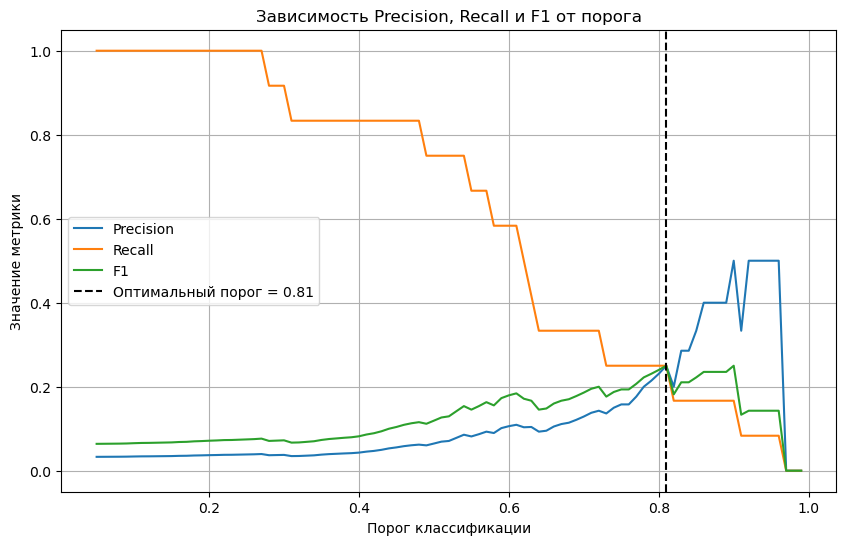

In [122]:
plt.figure(
    figsize=(10, 6)
)

plt.plot(
    threshold_results["threshold"],
    threshold_results["precision"],
    label="Precision"
)

plt.plot(
    threshold_results["threshold"],
    threshold_results["recall"],
    label="Recall"
)

plt.plot(
    threshold_results["threshold"],
    threshold_results["f1"],
    label="F1"
)

plt.axvline(
    best_threshold,
    linestyle="--",
    color="black",
    label=f"Оптимальный порог = {best_threshold:.2f}"
)

plt.xlabel(
    "Порог классификации"
)

plt.ylabel(
    "Значение метрики"
)

plt.title(
    "Зависимость Precision, Recall и F1 от порога"
)

plt.legend()
plt.grid()

plt.show()

## Ранжирование клиентов

In [123]:
# Рассчитываем вероятность покупки для всех клиентов целевой аудитории.

X_all = propensity_clients[
    features
].copy()

propensity_clients[
    "purchase_probability"
] = logistic_model.predict_proba(
    X_all
)[:, 1]

ranked_clients = (
    propensity_clients
    .sort_values(
        "purchase_probability",
        ascending=False
    )
    .reset_index(drop=True)
)

display(
    ranked_clients[
        [
            "id",
            "age",
            "education",
            "purchase_count",
            "total_spent",
            "average_check",
            "discount_share",
            "target",
            "purchase_probability"
        ]
    ]
    .head(20)
    .round(4)
)

,id,age,education,purchase_count,total_spent,average_check,discount_share,target,purchase_probability
0,101375,36,среднее,115,219230,1906.3478,0.4609,0,0.9994
1,99756,56,среднее,61,120532,1975.9344,0.6393,0,0.9929
2,158403,28,среднее,73,207692,2845.0959,0.2192,0,0.9916
3,41286,32,среднее,80,440489,5506.1125,0.5625,0,0.9853
4,158611,61,среднее,49,149971,3060.6327,0.6735,0,0.9784
5,88089,37,среднее,56,155675,2779.9107,0.6607,1,0.9646
6,101719,49,среднее,51,107587,2109.5490,0.2941,0,0.9442
7,78074,54,среднее,31,86822,2800.7097,0.5161,0,0.9209
8,6711,31,среднее,41,105514,2573.5122,0.4146,0,0.9201
9,18836,47,среднее,44,57096,1297.6364,0.5909,0,0.9187


## Top 1/5/10/20/30/50%

In [124]:
total_buyers = (
    ranked_clients["target"].sum()
)

results = []

for percent in [
    1,
    5,
    10,
    20,
    30,
    50
]:
    
    n = int(
        len(ranked_clients)
        * percent
        / 100
    )
    
    selected = (
        ranked_clients
        .head(n)
    )
    
    buyers_count = (
        selected["target"].sum()
    )
    
    buyer_share = (
        buyers_count
        / total_buyers
        * 100
    )
    
    conversion = (
        selected["target"].mean()
        * 100
    )
    
    avg_probability = (
        selected["purchase_probability"]
        .mean()
        * 100
    )
    
    results.append({
        "Аудитория": f"Top {percent}%",
        "Клиенты": len(selected),
        "Покупатели": int(buyers_count),
        "Охват покупателей, %": buyer_share,
        "Конверсия, %": conversion,
        "Средняя вероятность, %": avg_probability
    })

ranking_quality = pd.DataFrame(
    results
)

display(
    ranking_quality.round(2)
)

,Аудитория,Клиенты,Покупатели,"Охват покупателей, %","Конверсия, %","Средняя вероятность, %"
0,Top 1%,19,3,5.17,15.79,92.99
1,Top 5%,95,9,15.52,9.47,82.74
2,Top 10%,191,17,29.31,8.90,76.15
3,Top 20%,382,28,48.28,7.33,68.84
4,Top 30%,573,34,58.62,5.93,64.33
5,Top 50%,956,48,82.76,5.02,58.08


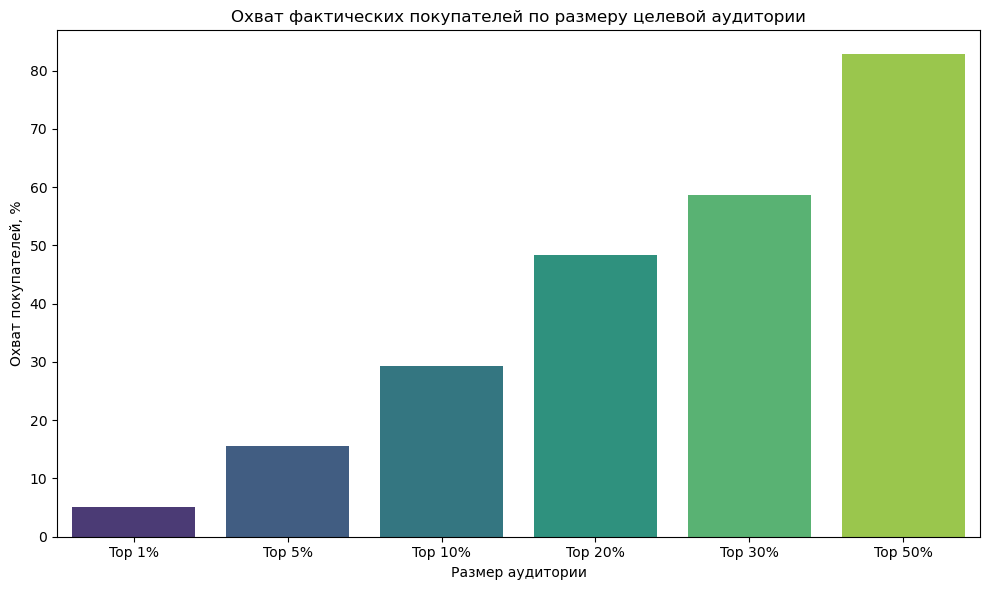

In [205]:
# Охват покупателей по размеру аудитории
plt.figure(figsize=(10, 6))

sns.barplot(
    data=ranking_quality,
    x="Аудитория",
    y="Охват покупателей, %",
    hue="Аудитория",
    palette="viridis",
    legend=False
)

plt.title(
    "Охват фактических покупателей по размеру целевой аудитории"
)

plt.xlabel("Размер аудитории")
plt.ylabel("Охват покупателей, %")

plt.tight_layout()
plt.show()

## Выбор оптимального размера маркетинговой аудитории

In [126]:
top_10_count = int(
    len(ranked_clients) * 0.10
)

top_10_clients = (
    ranked_clients
    .head(top_10_count)
)

print(
    "Top 10% клиентов:",
    len(top_10_clients)
)

print(
    "Фактических покупателей:",
    int(top_10_clients["target"].sum())
)

print(
    "Конверсия:",
    round(
        top_10_clients["target"].mean() * 100,
        2
    ),
    "%"
)

print(
    "Средняя вероятность:",
    round(
        top_10_clients["purchase_probability"].mean() * 100,
        2
    ),
    "%"
)

Top 10% клиентов: 191
Фактических покупателей: 17
Конверсия: 8.9 %
Средняя вероятность: 76.15 %


## Анализ коэффициентов модели

In [127]:
feature_names = (
    logistic_model
    .named_steps[
        "preprocessor"
    ]
    .get_feature_names_out()
)

coefficients = (
    logistic_model
    .named_steps[
        "classifier"
    ]
    .coef_[0]
)

feature_importance = pd.DataFrame({
    "feature": feature_names,
    "coefficient": coefficients
})

feature_importance[
    "abs_coefficient"
] = (
    feature_importance[
        "coefficient"
    ].abs()
)

feature_importance = (
    feature_importance
    .sort_values(
        "abs_coefficient",
        ascending=False
    )
)

display(
    feature_importance.round(4)
)

,feature,coefficient,abs_coefficient
3,num__average_check,-1.2243,1.2243
4,num__unique_products,0.4275,0.4275
8,cat__education_среднее,-0.4154,0.4154
2,num__total_spent,-0.3496,0.3496
7,cat__education_высшее,0.3065,0.3065
0,num__age,0.2951,0.2951
1,num__purchase_count,0.2177,0.2177
6,num__discount_share,0.0689,0.0689
5,num__discounted_purchases,0.0231,0.0231


In [128]:
# Отдельно показываем признаки,
# которые положительно и отрицательно влияют на вероятность покупки.

positive_features = (
    feature_importance[
        feature_importance["coefficient"] > 0
    ]
    .sort_values(
        "coefficient",
        ascending=False
    )
)

negative_features = (
    feature_importance[
        feature_importance["coefficient"] < 0
    ]
    .sort_values(
        "coefficient"
    )
)

print("Признаки, повышающие вероятность покупки:")

display(
    positive_features.round(4)
)

print(
    "Признаки, снижающие вероятность покупки:"
)

display(
    negative_features.round(4)
)

Признаки, повышающие вероятность покупки:


,feature,coefficient,abs_coefficient
4,num__unique_products,0.4275,0.4275
7,cat__education_высшее,0.3065,0.3065
0,num__age,0.2951,0.2951
1,num__purchase_count,0.2177,0.2177
6,num__discount_share,0.0689,0.0689
5,num__discounted_purchases,0.0231,0.0231


Признаки, снижающие вероятность покупки:


,feature,coefficient,abs_coefficient
3,num__average_check,-1.2243,1.2243
8,cat__education_среднее,-0.4154,0.4154
2,num__total_spent,-0.3496,0.3496


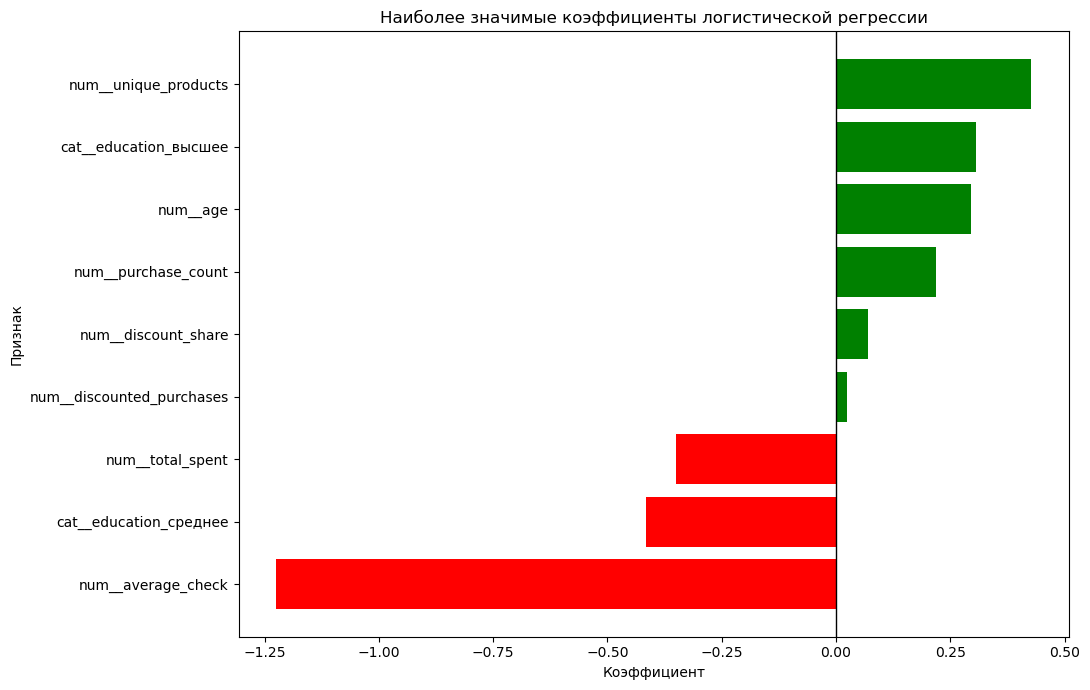

In [129]:
# Наиболее значимые коэффициенты модели
top_coefficients = (
    feature_importance
    .head(15)
    .sort_values(
        "coefficient"
    )
)

plt.figure(figsize=(11, 7))

colors = [
    "green"
    if value > 0
    else "red"
    for value in top_coefficients[
        "coefficient"
    ]
]

plt.barh(
    top_coefficients["feature"],
    top_coefficients["coefficient"],
    color=colors
)

plt.axvline(
    0,
    color="black",
    linewidth=1
)

plt.title(
    "Наиболее значимые коэффициенты логистической регрессии"
)

plt.xlabel("Коэффициент")
plt.ylabel("Признак")

plt.tight_layout()
plt.show()

## Финальная таблица клиентов для маркетинговой кампании

In [130]:
campaign_audience = (
    ranked_clients[
        [
            "id",
            "age",
            "education",
            "purchase_count",
            "total_spent",
            "average_check",
            "unique_products",
            "discount_share",
            "target",
            "purchase_probability"
        ]
    ]
    .copy()
)

campaign_audience["priority"] = np.select(
    [
        campaign_audience[
            "purchase_probability"
        ] >= 0.8,
        
        campaign_audience[
            "purchase_probability"
        ] >= 0.5,
        
        campaign_audience[
            "purchase_probability"
        ] >= 0.3
    ],
    [
        "Высокий",
        "Средний",
        "Низкий"
    ],
    default="Очень низкий"
)

display(
    campaign_audience.head(50).round(4)
)

,id,age,education,purchase_count,total_spent,average_check,unique_products,discount_share,target,purchase_probability,priority
0,101375,36,среднее,115,219230,1906.3478,75,0.4609,0,0.9994,Высокий
1,99756,56,среднее,61,120532,1975.9344,48,0.6393,0,0.9929,Высокий
2,158403,28,среднее,73,207692,2845.0959,63,0.2192,0,0.9916,Высокий
3,41286,32,среднее,80,440489,5506.1125,73,0.5625,0,0.9853,Высокий
4,158611,61,среднее,49,149971,3060.6327,41,0.6735,0,0.9784,Высокий
5,88089,37,среднее,56,155675,2779.9107,39,0.6607,1,0.9646,Высокий
6,101719,49,среднее,51,107587,2109.5490,28,0.2941,0,0.9442,Высокий
7,78074,54,среднее,31,86822,2800.7097,28,0.5161,0,0.9209,Высокий
8,6711,31,среднее,41,105514,2573.5122,33,0.4146,0,0.9201,Высокий
9,18836,47,среднее,44,57096,1297.6364,18,0.5909,0,0.9187,Высокий


In [206]:
print("ИТОГОВЫЙ БИЗНЕС-АНАЛИЗ")
print("=" * 70)

print(
    f"Количество клиентов в анализе: "
    f"{len(client_features)}"
)

print(
    f"Количество сегментов: "
    f"{client_features['cluster'].nunique()}"
)

print(
    f"Оптимальный порог propensity-модели: "
    f"{best_threshold:.2f}"
)

print(
    f"F1-score при оптимальном пороге: "
    f"{final_f1:.4f}"
)

top10_row = ranking_quality[
    ranking_quality["Аудитория"] == "Top 10%"
]

if len(top10_row) > 0:
    
    top10_row = top10_row.iloc[0]
    
    print(
        f"Top 10% клиентов: "
        f"{int(top10_row['Клиенты'])} клиентов"
    )
    
    print(
        f"Покупателей в Top 10%: "
        f"{int(top10_row['Покупатели'])}"
    )
    
    print(
        f"Охват покупателей: "
        f"{top10_row['Охват покупателей, %']:.2f}%"
    )
    
    print(
        f"Конверсия: "
        f"{top10_row['Конверсия, %']:.2f}%"
    )

print("=" * 70)

ИТОГОВЫЙ БИЗНЕС-АНАЛИЗ
Количество клиентов в анализе: 15748
Количество сегментов: 6
Оптимальный порог propensity-модели: 0.81
F1-score при оптимальном пороге: 0.2500
Top 10% клиентов: 191 клиентов
Покупателей в Top 10%: 17
Охват покупателей: 29.31%
Конверсия: 8.90%


## A/B-тестирование

In [207]:
# A/B тест: случайно делим клиентов на контрольную и тестовую группы

ab_test = propensity_clients.copy()

# Воспроизводимое случайное распределение 50/50
np.random.seed(42)

ab_test["group"] = np.random.choice(
    ["A", "B"],
    size=len(ab_test),
    p=[0.5, 0.5]
)

print("Распределение групп:")
print(ab_test["group"].value_counts())

print("\nРазмер групп:")
print(ab_test.groupby("group").size())

Распределение групп:
group
B    971
A    942
Name: count, dtype: int64

Размер групп:
group
A    942
B    971
dtype: int64


In [133]:
# Проверяем баланс контрольной и тестовой групп

balance = ab_test.groupby("group").agg(
    clients=("id", "count"),
    avg_age=("age", "mean"),
    avg_purchase_count=("purchase_count", "mean"),
    avg_total_spent=("total_spent", "mean"),
    avg_check=("average_check", "mean"),
    avg_unique_products=("unique_products", "mean"),
    avg_discount_share=("discount_share", "mean"),
    previous_buyers=("target", "sum")
).reset_index()

balance["previous_buyer_share"] = (
    balance["previous_buyers"] / balance["clients"]
)

display(balance)

,group,clients,avg_age,avg_purchase_count,avg_total_spent,avg_check,avg_unique_products,avg_discount_share,previous_buyers,previous_buyer_share
0,A,942,38.989384,7.312102,40214.128450,5943.712270,6.246285,0.326286,30,0.031847
1,B,971,38.598352,6.697219,35858.560247,5892.961052,5.938208,0.331686,28,0.028836


In [134]:
# Доля клиентов с предыдущей покупкой в каждой группе

ab_conversion = (
    ab_test.groupby("group")["target"]
    .mean()
    .reset_index()
)

ab_conversion["target"] = ab_conversion["target"] * 100

ab_conversion.columns = ["group", "previous_buyer_share_%"]

display(ab_conversion)

,group,previous_buyer_share_%
0,A,3.184713
1,B,2.883625


In [135]:
from scipy.stats import chi2_contingency

# Проверяем, есть ли статистически значимое различие
# по предыдущей покупке между группами A и B

contingency_table = pd.crosstab(
    ab_test["group"],
    ab_test["target"]
)

print("Таблица сопряженности:")
display(contingency_table)

chi2, p_value, dof, expected = chi2_contingency(contingency_table)

print(f"Chi-square statistic: {chi2:.4f}")
print(f"p-value: {p_value:.4f}")

if p_value < 0.05:
    print("Вывод: группы статистически значимо различаются.")
else:
    print("Вывод: статистически значимого различия между группами нет.")

Таблица сопряженности:


target,0,1
group,,
A,912,30
B,943,28


Chi-square statistic: 0.0628
p-value: 0.8021
Вывод: статистически значимого различия между группами нет.


Перед проведением кампании контрольная и тестовая группы были проверены на однородность по исторической конверсии. Статистически значимых различий между группами не выявлено (χ² = 0,063; p-value = 0,802). Это позволяет использовать сформированные группы для последующего A/B-тестирования.

In [136]:
# Размер выборки и ожидаемый эффект для будущего A/B-теста

baseline_conversion = ab_test["target"].mean()

print(f"Базовая конверсия: {baseline_conversion:.2%}")

print("\nРаспределение групп:")
print(ab_test["group"].value_counts())

print("\nТекущий baseline по группам:")
display(
    ab_test.groupby("group")["target"]
    .agg(["count", "sum", "mean"])
    .rename(columns={
        "count": "clients",
        "sum": "buyers",
        "mean": "conversion"
    })
)

Базовая конверсия: 3.03%

Распределение групп:
group
B    971
A    942
Name: count, dtype: int64

Текущий baseline по группам:


,clients,buyers,conversion
group,,,
A,942,30,0.031847
B,971,28,0.028836


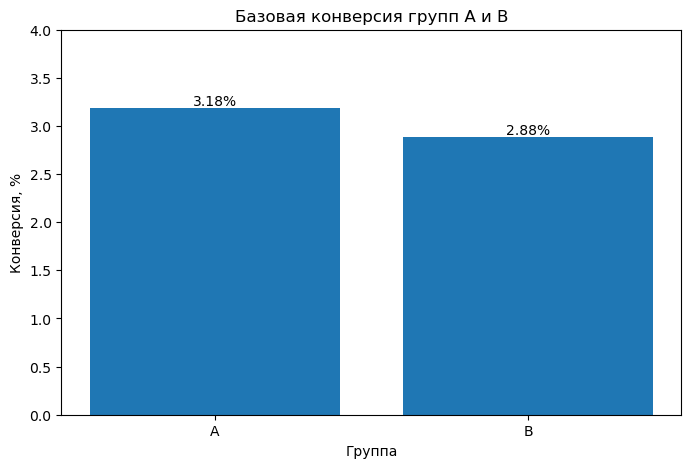

In [137]:
# Визуализация baseline-конверсии групп A и B

plt.figure(figsize=(8, 5))

bars = plt.bar(
    ab_conversion["group"],
    ab_conversion["previous_buyer_share_%"]
)

plt.title("Базовая конверсия групп A и B")
plt.xlabel("Группа")
plt.ylabel("Конверсия, %")

for bar, value in zip(
    bars,
    ab_conversion["previous_buyer_share_%"]
):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.03,
        f"{value:.2f}%",
        ha="center"
    )

plt.ylim(0, 4)
plt.show()

Базовая конверсия в контрольной группе составила 3,18%, в тестовой — 2,88%. Различие статистически незначимо (p-value = 0,802), поэтому группы можно считать сопоставимыми перед запуском маркетингового воздействия.

In [138]:
# Статистическая проверка различий между группами
from scipy.stats import chi2_contingency

contingency_table = pd.crosstab(
    ab_test["group"],
    ab_test["target"]
)

print("Таблица сопряженности:")
display(contingency_table)

chi2, p_value, dof, expected = chi2_contingency(contingency_table)

print(f"Chi-square statistic: {chi2:.4f}")
print(f"p-value: {p_value:.4f}")

if p_value < 0.05:
    print("Вывод: группы статистически значимо различаются.")
else:
    print("Вывод: статистически значимого различия между группами нет.")

Таблица сопряженности:


target,0,1
group,,
A,912,30
B,943,28


Chi-square statistic: 0.0628
p-value: 0.8021
Вывод: статистически значимого различия между группами нет.


In [139]:
# Итоговая проверка однородности групп

ab_summary = ab_test.groupby("group").agg(
    clients=("id", "count"),
    buyers=("target", "sum"),
    conversion=("target", "mean")
).reset_index()

ab_summary["conversion"] = ab_summary["conversion"] * 100

display(ab_summary)

print(
    "Вывод: статистически значимого различия между контрольной и "
    "тестовой группами на исходном уровне не выявлено "
    "(χ² = 0.0628, p-value = 0.8021)."
)

,group,clients,buyers,conversion
0,A,942,30,3.184713
1,B,971,28,2.883625


Вывод: статистически значимого различия между контрольной и тестовой группами на исходном уровне не выявлено (χ² = 0.0628, p-value = 0.8021).


### Дизайн A/B-теста

Цель эксперимента — проверить, повышает ли персонализированное предложение вероятность покупки товара «брюки мужские Demix» среди клиентов целевой аудитории.

**Контрольная группа (A)** получает стандартную коммуникацию без специального персонализированного предложения.

**Тестовая группа (B)** получает персонализированное предложение на товар «брюки мужские Demix». В первую очередь предложение рекомендуется направлять клиентам с высокой склонностью к покупке, определённой с помощью propensity-модели.

**Основная метрика эксперимента** — конверсия в покупку целевого товара.

**Дополнительные метрики** — выручка на одного клиента и, при наличии данных о себестоимости, валовая маржа на одного клиента.

Уровень статистической значимости — 5% (α = 0,05).

После завершения кампании конверсия групп A и B должна быть сравнена статистическим тестом для долей. Если p-value < 0,05, различие между группами считается статистически значимым.

### Метрики для оценки A/B-теста

После завершения рекламной кампании необходимо сравнить фактическую конверсию в покупку целевого товара в контрольной и тестовой группах.

Основной показатель — конверсия:

**Конверсия = количество клиентов, совершивших покупку / количество клиентов в группе**

Дополнительно необходимо рассчитать абсолютную и относительную разницу между группами:

**Абсолютный эффект = Конверсия B − Конверсия A**

**Относительный эффект = (Конверсия B − Конверсия A) / Конверсия A × 100%**

Статистическую значимость различий необходимо проверить с помощью критерия для сравнения двух долей при уровне значимости α = 0,05.

In [140]:
# Функция для расчёта результатов A/B-теста

def calculate_ab_metrics(data):
    summary = data.groupby("group")["target"].agg(
        clients="count",
        buyers="sum"
    ).reset_index()

    summary["conversion"] = (
        summary["buyers"] / summary["clients"]
    )

    return summary


ab_results = calculate_ab_metrics(ab_test)

display(ab_results)

,group,clients,buyers,conversion
0,A,942,30,0.031847
1,B,971,28,0.028836


In [141]:
# Расчёт разницы между группами

conversion_a = ab_results.loc[
    ab_results["group"] == "A", "conversion"
].iloc[0]

conversion_b = ab_results.loc[
    ab_results["group"] == "B", "conversion"
].iloc[0]

absolute_effect = conversion_b - conversion_a
relative_effect = absolute_effect / conversion_a * 100

print(f"Конверсия A: {conversion_a:.2%}")
print(f"Конверсия B: {conversion_b:.2%}")
print(f"Абсолютная разница: {absolute_effect:.2%}")
print(f"Относительная разница: {relative_effect:.2f}%")

Конверсия A: 3.18%
Конверсия B: 2.88%
Абсолютная разница: -0.30%
Относительная разница: -9.45%


### Ограничения A/B-теста

В имеющихся данных отсутствуют фактические результаты маркетинговой кампании после разделения клиентов на контрольную и тестовую группы. Поэтому текущие значения конверсии отражают исторические покупки и не являются результатом воздействия тестового предложения.

Полученная разница между группами составляет -0,30 процентного пункта, или -9,45% относительно контрольной группы. Однако данный показатель нельзя интерпретировать как эффект рекламной кампании.

Для оценки реального эффекта необходимо после проведения кампании собрать данные о новых покупках и повторно сравнить конверсию групп A и B.

### Вывод по A/B-тестированию

Контрольная и тестовая группы были сформированы случайным образом и проверены на сопоставимость. Историческая конверсия составила 3,18% в контрольной группе и 2,88% в тестовой.

Критерий χ² показал отсутствие статистически значимого различия между группами (χ² = 0,063; p-value = 0,802). Следовательно, группы можно считать сопоставимыми для проведения последующего эксперимента.

В качестве тестового воздействия предлагается использовать персонализированное предложение товара «брюки мужские Demix», сформированное с учётом propensity-модели. Основной метрикой эксперимента должна стать конверсия в покупку. Фактический эффект необходимо оценить после завершения кампании на новых данных.

## Итоговые выводы и рекомендации

### Основные результаты исследования

В ходе проекта был проведён комплексный анализ клиентской базы и истории покупок. Были выполнены подготовка и проверка данных, сегментация клиентов, анализ целевой аудитории, исследование зависимости покупок от скидок, построение propensity-модели и разработка дизайна A/B-теста.

Основные результаты:

1. В исходной клиентской базе содержится 15 748 клиентов. Для части клиентов отсутствуют записи о покупках, поэтому показатели покупательского поведения для таких клиентов были заполнены нулевыми значениями.

2. С помощью кластеризации клиенты были разделены на 6 сегментов, отличающихся по частоте покупок, суммарным расходам, среднему чеку, ассортименту покупок и чувствительности к скидкам.

3. Наиболее многочисленным сегментом является сегмент регулярных покупателей с низкой зависимостью от скидок — 5 369 клиентов (34,09%). Отдельно выделяется сегмент сверхактивных покупателей — 53 клиента (0,34%), которые совершают в среднем около 95 покупок и имеют высокую общую сумму покупок.

4. Целевая аудитория в выбранном городе и стране включает 1 913 клиентов. Среди наиболее популярных товаров целевой аудитории представлены товары Demix, Joss, Outventure, FILA и других брендов.

5. Целевой товар «брюки мужские Demix» ранее приобретали 58 клиентов из 1 913, что соответствует 3,03% аудитории.

6. Propensity-модель показала ROC-AUC = 0,765. Для практического использования рекомендуется ориентироваться не только на абсолютную вероятность, но и на ранжирование клиентов по склонности к покупке.

7. При выборе верхних 10% клиентов модель позволяет охватить 191 клиента и 29,31% всех известных покупателей целевого товара в тестовой выборке. Данный сегмент может использоваться как первоначальная аудитория для персонализированной кампании.

8. Анализ скидок показал, что разные сегменты по-разному реагируют на снижение цены. Наиболее высокая доля покупок со скидкой наблюдается у сегмента 1 — 62,23%. При этом VIP-клиенты и регулярные покупатели с низкой зависимостью от скидок чаще совершают покупки без скидок.

9. Для последующего A/B-тестирования были сформированы контрольная и тестовая группы. Статистически значимого различия в исторической конверсии между группами не обнаружено (χ² = 0,063; p-value = 0,802).

### Бизнес-рекомендации

На основании проведённого анализа рекомендуется:

**1. Использовать propensity-модель для приоритизации клиентов.**

Вместо массовой рассылки целесообразно сначала работать с клиентами с наиболее высокой склонностью к покупке целевого товара. В качестве первоначального охвата можно использовать верхние 10% рейтинга модели.

**2. Проводить персонализированные кампании.**

Для клиентов с высокой склонностью к покупке целесообразно использовать персонализированные предложения на основе их истории покупок и интереса к определённым категориям товаров.

**3. Не использовать одинаковые скидки для всех сегментов.**

Для чувствительных к скидкам клиентов можно тестировать ограниченные по времени скидки или специальные промокоды. Для клиентов, которые преимущественно покупают без скидок, предпочтительнее использовать рекомендации товаров, новые коллекции, комплекты и программы лояльности.

**4. Удерживать наиболее активных клиентов.**

Сверхактивные и VIP-клиенты формируют значительный объём покупок, поэтому для них важно применять механики удержания: персональные предложения, программы лояльности и рекомендации сопутствующих товаров.

**5. Проверять эффективность предложений через A/B-тестирование.**

Перед масштабированием рекламной кампании необходимо сравнивать персонализированное предложение со стандартной коммуникацией. Основной метрикой должна быть конверсия в покупку, а дополнительными — выручка и, при наличии данных, валовая маржа на одного клиента.

**6. Не оценивать эффективность только по конверсии.**

Рост количества покупок не всегда означает рост финансового результата. Поэтому после запуска кампании рекомендуется дополнительно контролировать выручку, средний чек и маржинальность.

**7. Проводить повторное обучение модели.**

По мере накопления новых данных о покупках propensity-модель необходимо периодически переобучать и проверять её качество на новых данных.

### Итоговый вывод

Проведённый анализ показывает, что клиентскую базу целесообразно разделять на сегменты и применять разные маркетинговые стратегии для каждой группы.

Наиболее перспективным подходом является сочетание сегментации, propensity-модели и контролируемых A/B-тестов. Propensity-модель позволяет определить клиентов с высокой склонностью к покупке, а A/B-тестирование — проверить, действительно ли персонализированное предложение приводит к дополнительным покупкам.

Таким образом, предложенный подход позволяет перейти от массового маркетинга к более адресной работе с клиентами и принимать решения на основе данных. Перед масштабированием кампаний необходимо подтвердить экономический эффект на новых данных с помощью A/B-тестирования.

## Сохраняем результаты

In [68]:
final_marketing_report.to_csv(
    "final_marketing_report.csv",
    index=False,
    encoding="utf-8-sig"
)

top_products_report.to_csv(
    "top_products_by_cluster.csv",
    index=False,
    encoding="utf-8-sig"
)

discount_summary.to_csv(
    "discount_summary.csv",
    index=False,
    encoding="utf-8-sig"
)

ranking_quality.to_csv(
    "propensity_ranking_quality.csv",
    index=False,
    encoding="utf-8-sig"
)

campaign_audience.to_csv(
    "campaign_audience.csv",
    index=False,
    encoding="utf-8-sig"
)

print("Результаты сохранены.")

Результаты сохранены.
